# 14 — MMLongBench-Doc benchmark: page retrieval and cited answers

## Objective

Run a small, reproducible benchmark loop on **MMLongBench-Doc**, a public long-document question-answering benchmark, and measure two separate things:

1. **Retrieval:** does a simple lexical retriever (BM25) find the annotated evidence pages of a question?
2. **Answering:** given the retrieved pages, does a language model produce the reference answer and cite only pages it was actually given?
3. **Diagnosis:** with the annotated evidence pages guaranteed to be in context (the *oracle-page condition*, Step 13), how many answer errors remain? This separates retrieval misses from reading errors.

Everything that defines a run (dataset revision, random seed, subset, retriever settings, prompt, model) is recorded and saved next to the outputs.

## Scope and honesty rules

- This is a **development subset** (a few documents sampled with a fixed seed), not the full 1,091-question benchmark. Numbers here describe this subset only.
- Answer scoring re-implements the benchmark's **rule-based scoring stage**. The official protocol additionally uses GPT-4o to extract a short answer from a free-form response; this notebook asks the model for a short structured answer instead. Answer scores are therefore **local diagnostics, not leaderboard-comparable results**.
- Answer generation runs only when a provider, a model name, and an API key are configured **and** `VISUALDOC_GENERATION_MODE` opts in (`smoke`, `pilot` or `full`). Otherwise the notebook stops at an explicit readiness gate and reports **no** answer metrics — it never substitutes mock answers.
- A failed API call is an infrastructure failure, not a wrong answer: if any question of the answer population has no model response, **no** answer metric is reported.

## Concept

### Pipeline

```text
question ─► BM25 over the page texts of its own PDF ─► top-k pages ─► LLM ─► {answer, cited_pages}
                         │                               │                    │
                         ▼                               ▼                    ▼
              Recall@k vs evidence_pages     citation validity/correctness   rule-based answer score
```

The retrieval unit is the **page**, matching the benchmark's `evidence_pages` annotation and the project's citation design (README §4). Retrieval is restricted to the PDF the question is about, because MMLongBench-Doc is single-document QA.

### Page numbering

`evidence_pages` stores integers such as `[5]`, while PyMuPDF indexes pages from 0. We treat benchmark page `p` as the **1-based physical page** `pdf[p - 1]` — but we do not simply assume it: Step 5 tests the convention against where the reference answers actually occur in the text.

### Unanswerable questions

About 22% of the questions have the reference answer `"Not answerable"` (with `answer_format == "None"`). They test whether a system abstains instead of guessing. They are:

- **excluded from retrieval metrics** — there is no evidence to find, even when a row lists pages;
- **included in answer metrics**, where the only correct prediction is `"Not answerable"`.

### Retrieval metrics

For a question with evidence pages $E$ and top-$k$ retrieved pages $R_k$:

$$\text{Recall@}k = \frac{|E \cap R_k|}{|E|}, \qquad \text{Hit@}k = \mathbf{1}\left[E \cap R_k \neq \varnothing\right].$$

Recall@k is the main metric because about a third of the benchmark's questions need several pages; Hit@k (notebook 07) only asks for one of them. Answer metrics are defined in Step 8.

## Setup

The notebook is self-contained: it rebuilds every operation it needs and does not import `src/visualdoc/` or state from other notebooks.

In [1]:
from collections import Counter
from datetime import datetime, timezone
from math import comb, isclose, log
from pathlib import Path
import ast
import hashlib
import json
import os
import platform
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf
from huggingface_hub import HfApi, hf_hub_download
from IPython.display import Markdown, display

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
MMLONG_DIR = PROJECT_ROOT / "data" / "external" / "mmlongbench_doc"
RUNS_DIR = PROJECT_ROOT / "experiments" / "runs" / "mmlongbench_doc"

print("Python:", sys.version.split()[0], "| PyMuPDF:", pymupdf.VersionBind, "| pandas:", pd.__version__, "| numpy:", np.__version__)
print("Project root folder:", PROJECT_ROOT.name)

Python: 3.12.6 | PyMuPDF: 2.1 | pandas: 3.1.1 | numpy: 2.3.5
Project root folder: Multimodal-Document-Intelligence


## Run settings

Every choice that can change a result lives in one dictionary, saved as `settings.json` with the outputs.

- `dataset_revision` pins the Hugging Face dataset commit, so the question table cannot change silently.
- `seed`, `n_documents` and `max_document_mb` fully determine the subset.
- `bm25_k1` and `bm25_b` are the textbook BM25 defaults; they are **not tuned** here.
- Model settings come from environment variables (or a git-ignored `.env` file), so no key is ever written into the notebook. `VISUALDOC_LLM_MODEL` has no default on purpose: the model choice is still an open project decision.

In [2]:
try:
    from dotenv import load_dotenv

    load_dotenv(PROJECT_ROOT / ".env")
except ImportError:
    pass  # python-dotenv is optional; plain environment variables still work

SETTINGS = {
    "dataset_repo": "yubo2333/MMLongBench-Doc",
    "dataset_revision": "2ff6aa9237fc777b6627dc57a486e9225ac5fb86",
    "seed": 42,
    "n_documents": 6,
    "max_document_mb": 15.0,
    "text_extraction": "native PyMuPDF text; Tesseract OCR via PyMuPDF for pages under the word threshold",
    "ocr_min_native_words": 30,
    "ocr_dpi": 150,
    "retriever": "BM25, Lucene-style idf, unique query terms, per-document statistics",
    "bm25_k1": 1.5,
    "bm25_b": 0.75,
    "k_values": [1, 3, 5, 10],
    "generation_top_k": 5,
    "max_chars_per_page": 3500,
    "model_provider": os.getenv("VISUALDOC_LLM_PROVIDER", "openai"),
    "model_name": os.getenv("VISUALDOC_LLM_MODEL") or None,
    "temperature": 0.0,
    "max_output_tokens": 400,
    "prompt_version": "mmlb-structured-v1",
    "scoring": "local re-implementation of MMLongBench-Doc eval/eval_score.py @ d73f0dc (rule-based stage only)",
    # How much of Step 9 calls the API. "off" makes no call; "smoke" makes one test call;
    # "pilot" = smoke test + `pilot_size` fixed questions; "full" = smoke test + every subset question.
    "generation_mode": os.getenv("VISUALDOC_GENERATION_MODE", "off"),
    "pilot_size": 5,
    # Step 13, run in pilot and full modes on the answerable questions of the answer population.
    "oracle_condition": "annotated evidence pages, padded to generation_top_k with the best-ranked non-evidence BM25 pages, in BM25 rank order",
    "max_attempts": 3,  # per request, transient errors only (rate limit, timeout, 5xx)
    "request_timeout_s": 60,
}
assert SETTINGS["generation_mode"] in {"off", "smoke", "pilot", "full"}, "VISUALDOC_GENERATION_MODE must be off, smoke, pilot or full"
SETTINGS

{'dataset_repo': 'yubo2333/MMLongBench-Doc',
 'dataset_revision': '2ff6aa9237fc777b6627dc57a486e9225ac5fb86',
 'seed': 42,
 'n_documents': 6,
 'max_document_mb': 15.0,
 'text_extraction': 'native PyMuPDF text; Tesseract OCR via PyMuPDF for pages under the word threshold',
 'ocr_min_native_words': 30,
 'ocr_dpi': 150,
 'retriever': 'BM25, Lucene-style idf, unique query terms, per-document statistics',
 'bm25_k1': 1.5,
 'bm25_b': 0.75,
 'k_values': [1, 3, 5, 10],
 'generation_top_k': 5,
 'max_chars_per_page': 3500,
 'model_provider': 'openai',
 'model_name': 'gpt-4o-mini',
 'temperature': 0.0,
 'max_output_tokens': 400,
 'prompt_version': 'mmlb-structured-v1',
 'scoring': 'local re-implementation of MMLongBench-Doc eval/eval_score.py @ d73f0dc (rule-based stage only)',
 'generation_mode': 'full',
 'pilot_size': 5,
 'oracle_condition': 'annotated evidence pages, padded to generation_top_k with the best-ranked non-evidence BM25 pages, in BM25 rank order',
 'max_attempts': 3,
 'request_time

## Step 1 — Inspect the benchmark schema

The question table is a single Parquet file (≈80 KB). `hf_hub_download` reuses the local copy when it matches the pinned revision and downloads it otherwise.

In [3]:
questions_path = hf_hub_download(
    repo_id=SETTINGS["dataset_repo"],
    repo_type="dataset",
    revision=SETTINGS["dataset_revision"],
    filename="data/train-00000-of-00001.parquet",
    local_dir=MMLONG_DIR,
)
raw = pd.read_parquet(questions_path)
raw.insert(0, "qid", [f"mmlb-{index:04d}" for index in raw.index])

print("Shape:", raw.shape)
display(pd.DataFrame({"dtype": raw.dtypes.astype(str), "first row": raw.iloc[0]}))

Shape: (1091, 8)


,dtype,first row
qid,str,mmlb-0000
doc_id,str,PH_2016.06.08_Economy-Final.pdf
doc_type,str,Research report / Introduction
question,str,"According to the report, how do 5% of the Latinos see economic upward mobili..."
answer,str,Less well-off
evidence_pages,str,[5]
evidence_sources,str,['Chart']
answer_format,str,Str


Two details matter before any computation:

- `evidence_pages` and `evidence_sources` look like lists but are stored as **strings** (`'[5]'`). `ast.literal_eval` parses Python literals safely — unlike `eval`, it cannot execute code.
- The dataset has no question id, so we use the row position (`qid = mmlb-0000…`). This id is stable **only together with the pinned revision**.

In [4]:
print("Stored:", repr(raw.loc[0, "evidence_pages"]), "-> parsed:", ast.literal_eval(raw.loc[0, "evidence_pages"]))

bench = raw.copy()
bench["evidence_pages"] = bench["evidence_pages"].map(ast.literal_eval)
bench["evidence_sources"] = bench["evidence_sources"].map(ast.literal_eval)
bench["answerable"] = bench["answer"] != "Not answerable"
bench["n_evidence_pages"] = bench["evidence_pages"].map(len)

assert bench["evidence_pages"].map(lambda pages: all(isinstance(page, int) for page in pages)).all()
assert (bench.loc[~bench["answerable"], "answer_format"] == "None").all()
assert (bench.loc[bench["answerable"], "answer_format"] != "None").all()

display(pd.crosstab(bench["answer_format"], bench["answerable"], margins=True))
print(
    "Unanswerable questions that still list evidence pages:",
    int((~bench["answerable"] & (bench["n_evidence_pages"] > 0)).sum()),
)
print("Answerable questions with no evidence page:", int((bench["answerable"] & (bench["n_evidence_pages"] == 0)).sum()))
print("Questions citing page 0 anywhere:", int(bench["evidence_pages"].map(lambda pages: 0 in pages).sum()))

Stored: '[5]' -> parsed: [5]


answerable,False,True,All
answer_format,,,
Float,0,160,160
Int,0,290,290
List,0,147,147
None,244,0,244
Str,0,250,250
All,244,847,1091


Unanswerable questions that still list evidence pages: 7
Answerable questions with no evidence page: 9
Questions citing page 0 anywhere: 3


### Interpretation

- **847 answerable and 244 unanswerable questions (22.4%).** Every unanswerable row has `answer_format == "None"` and no answerable row does. The format column therefore *reveals* unanswerability, which is why it must never be shown to the model (Step 9).
- **7 unanswerable rows still list evidence pages, and 9 answerable rows list none.** Neither group can be scored for retrieval, so Step 7 defines the retrieval population explicitly instead of trusting the column.
- **3 rows cite page 0.** Under a 1-based convention that page does not exist. We treat these as annotation errors and exclude them from retrieval metrics rather than silently reinterpreting them.

## Step 2 — Verify document availability

Before sampling, list the PDFs on the Hub at the pinned revision **without downloading them**. Their sizes let us bound the download, and the check fails loudly if a question refers to a missing PDF.

In [5]:
hub_files = HfApi().list_repo_tree(
    SETTINGS["dataset_repo"],
    path_in_repo="documents",
    repo_type="dataset",
    revision=SETTINGS["dataset_revision"],
)
hub_sizes_mb = pd.Series(
    {Path(item.path).name: item.size / 1e6 for item in hub_files if item.path.endswith(".pdf")},
    name="size_mb",
)
local_pdfs = {path.name for path in (MMLONG_DIR / "documents").glob("*.pdf")}
referenced = set(bench["doc_id"])

availability = pd.DataFrame(
    [
        {"check": "documents referenced by questions", "value": len(referenced)},
        {"check": "referenced documents on the Hub", "value": len(referenced & set(hub_sizes_mb.index))},
        {"check": "referenced documents already local", "value": len(referenced & local_pdfs)},
        {"check": f"documents <= {SETTINGS['max_document_mb']:.0f} MB", "value": int((hub_sizes_mb <= SETTINGS["max_document_mb"]).sum())},
        {"check": "total size of all PDFs (MB)", "value": round(hub_sizes_mb.sum(), 1)},
    ]
)
display(availability)

missing_on_hub = sorted(referenced - set(hub_sizes_mb.index))
assert not missing_on_hub, f"Questions reference PDFs absent from the Hub: {missing_on_hub[:5]}"

,check,value
0,documents referenced by questions,135.0
1,referenced documents on the Hub,135.0
2,referenced documents already local,7.0
3,documents <= 15 MB,125.0
4,total size of all PDFs (MB),662.1


## Step 3 — A small, reproducible development subset

**What:** sample whole documents with a fixed seed, then keep every question about them.

**Why documents rather than questions:** each sampled PDF must be downloaded and parsed. Sampling 6 documents gives roughly 50 questions for a bounded download, and all questions on a document share the same retrieval corpus.

**Trade-offs to remember when reading the numbers:**

- Questions about the same document are correlated (same layout, same writing style), so the subset behaves more like 6 independent units than like 50. Differences of a few percentage points are noise.
- The size filter excludes the largest PDFs, which may be the longest and hardest documents. The comparison table below shows how the subset differs from the full benchmark.
- `sorted(...)` before sampling makes the result independent of file-listing order, and `numpy.random.default_rng(seed)` makes it independent of any global random state.

In [6]:
eligible_documents = sorted(
    doc_id for doc_id in referenced if hub_sizes_mb.get(doc_id, np.inf) <= SETTINGS["max_document_mb"]
)
rng = np.random.default_rng(SETTINGS["seed"])
subset_documents = sorted(rng.choice(eligible_documents, size=SETTINGS["n_documents"], replace=False).tolist())

subset = bench[bench["doc_id"].isin(subset_documents)].reset_index(drop=True)
document_table = (
    subset.groupby("doc_id")
    .agg(
        doc_type=("doc_type", "first"),
        questions=("qid", "size"),
        unanswerable=("answerable", lambda answerable: int((~answerable).sum())),
    )
    .assign(size_mb=lambda frame: hub_sizes_mb.reindex(frame.index).round(2))
)
print(f"Eligible documents: {len(eligible_documents)} | sampled: {len(subset_documents)} | questions: {len(subset)}")
document_table

Eligible documents: 125 | sampled: 6 | questions: 57


,doc_type,questions,unanswerable,size_mb
doc_id,,,,
2210.02442v1.pdf,Academic paper,9,3,4.70
PG_2020.05.21_International-Cooperation-COVID_FINAL.pdf,Research report / Introduction,11,4,3.30
bdf54dxa.pdf,Guidebook,7,2,7.67
earlybird-110722143746-phpapp02_95.pdf,Research report / Introduction,9,2,4.04
germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf,Research report / Introduction,16,5,1.46
watch_d.pdf,Guidebook,5,1,0.39


In [7]:
def percentage_share(series):
    return series.value_counts(normalize=True).mul(100).round(1)


comparison = pd.concat(
    {"full benchmark %": percentage_share(bench["answer_format"]), "subset %": percentage_share(subset["answer_format"])},
    axis=1,
).fillna(0)
comparison.loc["cross-page answerable"] = [
    round(100 * ((frame["n_evidence_pages"] > 1) & frame["answerable"]).mean(), 1) for frame in (bench, subset)
]
comparison.loc["question count"] = [len(bench), len(subset)]
comparison

,full benchmark %,subset %
answer_format,,
Int,26.6,38.6
Str,22.9,14.0
None,22.4,29.8
Float,14.7,12.3
List,13.5,5.3
cross-page answerable,33.0,31.6
question count,1091.0,57.0


Download the sampled PDFs at the pinned revision (skipped when already present), open each one, and check that every evidence page exists in its file. PDFs land in `data/external/mmlongbench_doc/documents/`, which is git-ignored because the benchmark data is licensed CC BY-NC 4.0.

In [8]:
pdf_paths = {
    doc_id: Path(
        hf_hub_download(
            repo_id=SETTINGS["dataset_repo"],
            repo_type="dataset",
            revision=SETTINGS["dataset_revision"],
            filename=f"documents/{doc_id}",
            local_dir=MMLONG_DIR,
        )
    )
    for doc_id in subset_documents
}

page_counts = {}
for doc_id, path in pdf_paths.items():
    with pymupdf.open(path) as pdf:
        page_counts[doc_id] = pdf.page_count

subset["page_count"] = subset["doc_id"].map(page_counts)
subset["max_evidence_page"] = subset["evidence_pages"].map(lambda pages: max(pages, default=0))
out_of_range = subset[subset["max_evidence_page"] > subset["page_count"]]
assert out_of_range.empty, out_of_range[["qid", "evidence_pages", "page_count"]]

document_table["pages"] = document_table.index.map(page_counts)
document_table

,doc_type,questions,unanswerable,size_mb,pages
doc_id,,,,,
2210.02442v1.pdf,Academic paper,9,3,4.70,24
PG_2020.05.21_International-Cooperation-COVID_FINAL.pdf,Research report / Introduction,11,4,3.30,26
bdf54dxa.pdf,Guidebook,7,2,7.67,54
earlybird-110722143746-phpapp02_95.pdf,Research report / Introduction,9,2,4.04,41
germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf,Research report / Introduction,16,5,1.46,23
watch_d.pdf,Guidebook,5,1,0.39,27


## Step 4 — Extract and inspect document content

**Native text first.** The same PyMuPDF call as notebooks 06–08 reads the text objects stored in the PDF.

**OCR fallback.** A first execution of this notebook showed that half of the sampled PDFs are slide decks exported as images: their pages contain no text objects at all, so a text retriever sees empty pages. For any page with fewer than `ocr_min_native_words` native words, we therefore render the page and run Tesseract OCR (through PyMuPDF, with the project's `resources/tessdata/eng.traineddata`, as in notebook 04).

Both texts are kept: `native_text` for the native-only ablation in Step 7, and `text` (native, or OCR when the page was below the threshold) for the main pipeline. The threshold of 30 words is a simple heuristic, not a tuned value; notebook 03 discusses better routing rules.

In [9]:
TESSDATA_DIR = PROJECT_ROOT / "resources" / "tessdata"
assert (TESSDATA_DIR / "eng.traineddata").is_file(), "OCR model missing: resources/tessdata/eng.traineddata"

page_rows = []
extraction_started = datetime.now(timezone.utc)
for doc_id, path in pdf_paths.items():
    with pymupdf.open(path) as pdf:
        for index, page in enumerate(pdf):
            native_text = page.get_text("text", sort=True)
            native_words = len(native_text.split())
            ocr_used = native_words < SETTINGS["ocr_min_native_words"]
            if ocr_used:
                # `page` must stay referenced while its OCR text page is read: PyMuPDF keeps only a weak reference.
                ocr_textpage = page.get_textpage_ocr(language="eng", dpi=SETTINGS["ocr_dpi"], full=True, tessdata=str(TESSDATA_DIR))
                text = page.get_text("text", textpage=ocr_textpage, sort=True)
            else:
                text = native_text
            page_rows.append(
                {
                    "doc_id": doc_id,
                    "page": index + 1,  # 1-based physical page number (convention tested in Step 5)
                    "native_text": native_text,
                    "native_words": native_words,
                    "ocr_used": ocr_used,
                    "text": text,
                    "words": len(text.split()),
                    "images": len(page.get_images(full=False)),
                }
            )
pages = pd.DataFrame(page_rows)
extraction_seconds = (datetime.now(timezone.utc) - extraction_started).total_seconds()

extraction_summary = pages.groupby("doc_id").agg(
    pages=("page", "size"),
    pages_with_images=("images", lambda images: int((images > 0).sum())),
    median_native_words=("native_words", "median"),
    pages_ocr=("ocr_used", "sum"),
    median_words_after_ocr=("words", "median"),
)
print(f"Extraction time: {extraction_seconds:.0f} s for {len(pages)} pages, of which {int(pages['ocr_used'].sum())} were OCR'd")
extraction_summary

Image too small to scale!! (2x36 vs min width of 3)
Line cannot be recognized!!


Extraction time: 61 s for 195 pages, of which 120 were OCR'd


,pages,pages_with_images,median_native_words,pages_ocr,median_words_after_ocr
doc_id,,,,,
2210.02442v1.pdf,24,7,473.0,0,473.0
PG_2020.05.21_International-Cooperation-COVID_FINAL.pdf,26,15,289.0,1,289.0
bdf54dxa.pdf,54,2,0.0,53,158.0
earlybird-110722143746-phpapp02_95.pdf,41,41,0.0,41,45.0
germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf,23,23,0.0,23,81.0
watch_d.pdf,27,12,300.0,2,300.0


One question end to end: the reference record, the extracted text of its evidence page, and the rendered page. The example is the first answerable single-page question in the subset, so it is chosen by rule, not by hand.

**mmlb-0033** · `earlybird-110722143746-phpapp02_95.pdf` · format `Int` · sources ['Chart', 'Table']

**Question:** How many more millions of dollars was the median exit valuation in the USA compared to Europe at the time of the presentation?

**Reference answer:** 63 · **evidence page:** 6

Native words on this page: 0 | text source used: OCR
At the same time,e    real performanceGg        shows
European VCa   | drivingee   the best exito multiplese
globally


  Exits over $ 100M
 2005 - Q1/2011





                                                             7.2

                                                                           Median Multiple
                                                                                             of Cash Invested                        45
                                                                                                                                                  Median Multiple
                                                                                                                                                                                                of Cash Invested

  Proportionally Europe
   is producing higher exit
  multiples and, although
  average exit values are
  ca. 25% smaller

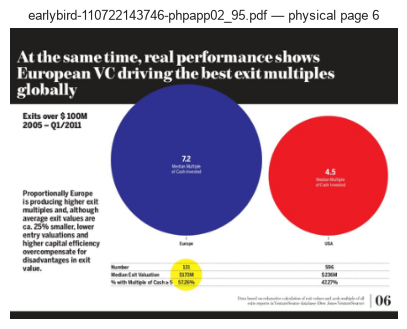

In [10]:
example = subset[subset["answerable"] & (subset["n_evidence_pages"] == 1)].iloc[0]
example_page = example["evidence_pages"][0]
example_page_row = pages[(pages["doc_id"] == example["doc_id"]) & (pages["page"] == example_page)].iloc[0]
example_text = example_page_row["text"]

display(
    Markdown(
        f"**{example['qid']}** · `{example['doc_id']}` · format `{example['answer_format']}` · sources {example['evidence_sources']}\n\n"
        f"**Question:** {example['question']}\n\n"
        f"**Reference answer:** {example['answer']} · **evidence page:** {example_page}"
    )
)
print(f"Native words on this page: {example_page_row['native_words']} | text source used: {'OCR' if example_page_row['ocr_used'] else 'native'}")
print(example_text[:1200])

with pymupdf.open(pdf_paths[example["doc_id"]]) as pdf:
    pixmap = pdf[example_page - 1].get_pixmap(matrix=pymupdf.Matrix(0.6, 0.6), alpha=False)
pixels = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.height, pixmap.width, pixmap.n)
fig, ax = plt.subplots(figsize=(5, 6.5))
ax.imshow(pixels)
ax.set_title(f"{example['doc_id']} — physical page {example_page}", fontsize=9)
ax.axis("off")
plt.show()

### Interpretation

- **Half of the sampled documents are image-only.** `bdf54dxa`, `earlybird` and `germanwings` have 0 native words on nearly every page (117 of their 118 pages needed OCR). Without OCR, both a text retriever and a text-only LLM would see empty pages. This is the scanned-page failure the README describes, observed at benchmark scale.
- **OCR makes pages searchable, but the text is noisy.** On the example page it produces fragments such as `exito multiplese`, loses the layout, and turns the chart value `4.5` into `45`.
- **The reference answer is not written on the page.** `63` is the difference between the two median exit valuations in the small table under the chart ($236M − $173M). OCR recovers `$236M` but only `173` (without `$` and `M`), and the model must still find both values and subtract them. Retrieval can succeed on this question while a text-only model still has to infer the comparison from noisy fragments, which makes it a natural test for the planned multimodal condition.
- **Cost:** OCR of 120 pages took about 40 s on this machine (single process, 150 dpi).

## Step 5 — Test the page-numbering convention

**Hypothesis:** benchmark page `p` is PyMuPDF index `p - 1` (1-based physical pages). If the benchmark were 0-based, its page `p` would be our page `p + 1`; if it had an off-by-one the other way, our page `p - 1`.

**Test:** take answerable questions whose reference answer is a distinctive short string (at least 3 characters, not a list) and search for it, as a whole token sequence, in the extracted text of each evidence page under the three alignments. The alignment that contains the answer most often is the convention. Answers that live only in figures will not be found under any alignment; that reduces the sample but does not favour any hypothesis.

In [11]:
def normalize_text(text):
    return re.sub(r"\s+", " ", str(text).lower()).strip()


def answer_pattern(answer):
    # Whole-token match: the answer "12" must not match inside "2012".
    return re.compile(r"(?<![0-9a-z])" + re.escape(normalize_text(answer)) + r"(?![0-9a-z])")


normalized_pages = {(row.doc_id, row.page): normalize_text(row.text) for row in pages.itertuples()}
alignments = {"page p - 1": -1, "page p (1-based hypothesis)": 0, "page p + 1 (0-based hypothesis)": 1}

probe = subset[subset["answerable"] & (subset["answer_format"] != "List") & (subset["answer"].str.len() >= 3)]
alignment_rows = []
for row in probe.itertuples():
    pattern = answer_pattern(row.answer)
    found = {
        label: any(pattern.search(normalized_pages.get((row.doc_id, page + offset), "")) for page in row.evidence_pages)
        for label, offset in alignments.items()
    }
    found["anywhere in the document"] = any(
        pattern.search(text) for (doc_id, _), text in normalized_pages.items() if doc_id == row.doc_id
    )
    alignment_rows.append(found)

alignment = pd.DataFrame(alignment_rows)
print("Probe questions:", len(alignment))
alignment.sum().rename("questions where the answer string is found").to_frame()

Probe questions: 17


,questions where the answer string is found
page p - 1,3
page p (1-based hypothesis),6
page p + 1 (0-based hypothesis),3
anywhere in the document,9


In [12]:
found_counts = alignment.sum()
assert found_counts["page p (1-based hypothesis)"] > found_counts["page p + 1 (0-based hypothesis)"]
assert found_counts["page p (1-based hypothesis)"] > found_counts["page p - 1"]
print("Convention check passed: benchmark page p == pdf[p - 1].")

Convention check passed: benchmark page p == pdf[p - 1].


### Interpretation

The answer string is found most often on page `p` under the 1-based alignment (6 of 17 probe questions, versus 3 and 3 for the shifted alignments) and somewhere in the document for 9. This favours the 1-based convention, but it is **weak evidence on its own**: few short answers occur verbatim, OCR text is noisy, and neighbouring slides often repeat the same numbers. Step 7 adds an independent check with the retriever.

## Step 6 — BM25 retrieval baseline

**Why BM25 instead of notebook 06's raw term-frequency cosine?** In long documents, raw counts reward long pages and common words. BM25 corrects both:

$$\text{score}(q, d) = \sum_{t \in q} \text{idf}(t)\,\frac{f(t,d)\,(k_1+1)}{f(t,d) + k_1\left(1 - b + b\,\frac{|d|}{\text{avgdl}}\right)}, \qquad \text{idf}(t) = \ln\left(1 + \frac{N - n_t + 0.5}{n_t + 0.5}\right)$$

- **idf:** a word on 2 of 80 pages is informative; a word on all 80 is not. The `1 +` inside the logarithm (Lucene's variant) keeps idf positive.
- **saturation ($k_1$):** the tenth occurrence of a word adds less than the first.
- **length normalisation ($b$):** a long page does not win merely by containing more words.

$N$, $n_t$ and avgdl are computed **per PDF**, because a question is only asked about its own document.

**Alternatives:** dense embeddings match paraphrases but need a model choice (still open in the README); vision retrievers such as ColPali read page images but are out of scope for this baseline. BM25 needs no training, no API and no GPU, and is deterministic — a transparent floor that later methods must beat.

First the underlying operation for one document, step by step:

In [13]:
TOKEN_PATTERN = re.compile(r"[a-z0-9]+")


def tokenize(text):
    return TOKEN_PATTERN.findall(str(text).lower())


doc_pages = pages[pages["doc_id"] == example["doc_id"]]
page_tokens = {row.page: tokenize(row.text) for row in doc_pages.itertuples()}
N = len(page_tokens)
avgdl = np.mean([len(tokens) for tokens in page_tokens.values()])
document_frequency = Counter(token for tokens in page_tokens.values() for token in set(tokens))
idf = {token: log(1 + (N - n_t + 0.5) / (n_t + 0.5)) for token, n_t in document_frequency.items()}

print(f"{example['doc_id']}: N={N} pages, avgdl={avgdl:.0f} tokens, vocabulary={len(idf):,} terms")
query_terms = sorted(set(tokenize(example["question"])))
pd.DataFrame(
    {
        "term": query_terms,
        "pages containing it (n_t)": [document_frequency.get(term, 0) for term in query_terms],
        "idf": [round(idf.get(term, 0.0), 3) for term in query_terms],
    }
).sort_values("idf", ascending=False).reset_index(drop=True)

earlybird-110722143746-phpapp02_95.pdf: N=41 pages, avgdl=57 tokens, vocabulary=1,105 terms


,term,pages containing it (n_t),idf
0,millions,1,3.332
1,valuation,2,2.821
2,time,2,2.821
3,many,3,2.485
4,usa,3,2.485
5,median,3,2.485
6,was,3,2.485
7,exit,4,2.234
8,more,6,1.866
9,at,8,1.598


In [14]:
k1, b = SETTINGS["bm25_k1"], SETTINGS["bm25_b"]


def term_contributions(query_terms, tokens):
    counts = Counter(tokens)
    length_factor = k1 * (1 - b + b * len(tokens) / max(avgdl, 1.0))
    return {
        term: idf[term] * counts[term] * (k1 + 1) / (counts[term] + length_factor)
        for term in query_terms
        if counts[term]
    }


page_scores = {page: sum(term_contributions(query_terms, tokens).values()) for page, tokens in page_tokens.items()}
top_pages = sorted(page_scores, key=lambda page: (-page_scores[page], page))[:5]
print("Top-5 pages:", top_pages, "| evidence page:", example_page)

breakdown = (
    pd.DataFrame({f"page {page}": term_contributions(query_terms, page_tokens[page]) for page in [example_page, *top_pages[:2]]})
    .fillna(0)
    .round(2)
)
breakdown.loc["TOTAL"] = breakdown.sum()
breakdown

Top-5 pages: [6, 27, 2, 26, 30] | evidence page: 6


,page 6,page 27
at,1.33,1.32
europe,0.84,1.00
exit,3.72,2.78
in,0.27,0.40
median,3.72,0.00
of,1.08,0.89
the,0.53,0.70
time,2.35,0.00
usa,2.07,2.05
valuation,2.35,0.00


### Interpretation

The evidence page 6 ranks first. The breakdown shows why: rare terms in this 41-page deck (`median`, `valuation`, `time`, idf ≈ 2.3–3.3) occur on page 6 but not on page 27, whereas page 27 scores mostly through more common words (`to`, `was`). Question words that appear on no page (`dollars`, `compared`, `presentation`) contribute nothing, and BM25 cannot match `dollars` to the `$` sign. This ranking exists only because of OCR: on native text every page of this deck scores 0, and the ranking falls back to page order.

The same computation is now wrapped into two helpers — one that builds the per-PDF statistics and one that ranks pages — and checked against the step-by-step scores above.

In [15]:
def build_bm25_index(page_texts):
    """page_texts: {page_number: text} for one PDF. Returns the statistics BM25 needs."""
    tokens = {page: tokenize(text) for page, text in page_texts.items()}
    n_pages = len(tokens)
    frequency = Counter(token for page_tokens in tokens.values() for token in set(page_tokens))
    return {
        "term_counts": {page: Counter(page_tokens) for page, page_tokens in tokens.items()},
        "lengths": {page: len(page_tokens) for page, page_tokens in tokens.items()},
        "avgdl": float(np.mean([len(page_tokens) for page_tokens in tokens.values()])),
        "idf": {token: log(1 + (n_pages - n_t + 0.5) / (n_t + 0.5)) for token, n_t in frequency.items()},
    }


def bm25_rank(index, query, k1=SETTINGS["bm25_k1"], b=SETTINGS["bm25_b"]):
    """Return [(page, score), ...] for every page, best first; ties are broken by page number."""
    terms = set(tokenize(query))
    scored = []
    for page, counts in index["term_counts"].items():
        length_factor = k1 * (1 - b + b * index["lengths"][page] / max(index["avgdl"], 1.0))
        score = sum(
            index["idf"][term] * counts[term] * (k1 + 1) / (counts[term] + length_factor) for term in terms if counts[term]
        )
        scored.append((page, score))
    return sorted(scored, key=lambda item: (-item[1], item[0]))


def rank_subset(text_column):
    """Build one BM25 index per PDF from `text_column` and rank every page for every subset question."""
    indexes = {
        doc_id: build_bm25_index(dict(zip(group["page"].tolist(), group[text_column])))
        for doc_id, group in pages.groupby("doc_id")
    }
    rankings = [[page for page, _ in bm25_rank(indexes[row.doc_id], row.question)] for row in subset.itertuples()]
    return indexes, pd.Series(rankings, index=subset.index, dtype=object)


bm25_indexes, subset["ranking"] = rank_subset("text")  # main condition: native text + OCR fallback
_, subset["ranking_native"] = rank_subset("native_text")  # ablation: native text only

# The helper must reproduce the step-by-step computation exactly.
helper_scores = dict(bm25_rank(bm25_indexes[example["doc_id"]], example["question"]))
assert all(isclose(helper_scores[page], page_scores[page], abs_tol=1e-12) for page in page_scores)

max_k = max(SETTINGS["k_values"])
subset[["qid", "doc_id", "evidence_pages", "ranking"]].assign(ranking=lambda frame: frame["ranking"].map(lambda r: r[:max_k])).head(6)

,qid,doc_id,evidence_pages,ranking
0,mmlb-0033,earlybird-110722143746-phpapp02_95.pdf,[6],"[6, 27, 2, 26, 30, 33, 28, 39, 38, 10]"
1,mmlb-0034,earlybird-110722143746-phpapp02_95.pdf,[11],"[11, 6, 26, 2, 27, 33, 17, 7, 19, 31]"
2,mmlb-0035,earlybird-110722143746-phpapp02_95.pdf,"[11, 13, 15, 16, 21, 22, 23, 24, 25, 26, 27, 31, 38]","[39, 9, 30, 2, 31, 18, 11, 22, 10, 16]"
3,mmlb-0036,earlybird-110722143746-phpapp02_95.pdf,"[14, 19, 20, 33, 37]","[38, 30, 2, 5, 7, 23, 39, 10, 6, 26]"
4,mmlb-0037,earlybird-110722143746-phpapp02_95.pdf,[33],"[31, 32, 19, 30, 13, 17, 33, 34, 39, 2]"
5,mmlb-0038,earlybird-110722143746-phpapp02_95.pdf,[],"[19, 31, 13, 30, 17, 2, 32, 34, 27, 33]"


## Step 7 — Evaluate retrieval

**Population:** answerable questions with at least one evidence page. Unanswerable questions are excluded (Concept section), and so are the rare rows citing page `0`, which cannot exist under the 1-based convention (3 such rows in the full benchmark; they are annotation errors, not evidence).

**Two text conditions** use the same BM25 settings: *native-only* text versus *native + OCR fallback*. The difference isolates what OCR adds to retrieval.

**Random-ranking reference.** A number such as Recall@5 = 0.4 means little without knowing the document length. If the $n$ pages were ranked uniformly at random, each evidence page would land in the top $k$ with probability $\min(k,n)/n$, so

$$\mathbb{E}[\text{Recall@}k] = \frac{\min(k, n)}{n}, \qquad \mathbb{E}[\text{Hit@}k] = 1 - \frac{\binom{n-|E|}{k}}{\binom{n}{k}}.$$

These are exact expectations, not simulations; they show how much BM25 adds beyond chance on documents of this length.

In [16]:
def recall_at_k(evidence, ranking, k):
    evidence = set(evidence)
    return len(evidence & set(ranking[:k])) / len(evidence)


def hit_at_k(evidence, ranking, k):
    return float(bool(set(evidence) & set(ranking[:k])))


def random_hit_at_k(n_pages, n_evidence, k):
    if k >= n_pages:
        return 1.0
    return 1 - comb(n_pages - n_evidence, k) / comb(n_pages, k)


retrieval_population = subset[subset["answerable"] & (subset["n_evidence_pages"] > 0)].copy()
cites_page_zero = retrieval_population["evidence_pages"].map(lambda evidence: 0 in evidence)
print("Excluded for citing page 0:", int(cites_page_zero.sum()))
retrieval_population = retrieval_population[~cites_page_zero]

native_word_lookup = pages.set_index(["doc_id", "page"])["native_words"]
retrieval_population["evidence_native_words"] = [
    float(np.mean([native_word_lookup[(doc_id, page)] for page in evidence]))
    for doc_id, evidence in zip(retrieval_population["doc_id"], retrieval_population["evidence_pages"])
]
evidence = retrieval_population["evidence_pages"]
for k in SETTINGS["k_values"]:
    for prefix, ranking_column in [("", "ranking"), ("native_", "ranking_native")]:
        rankings = retrieval_population[ranking_column]
        retrieval_population[f"{prefix}recall@{k}"] = [recall_at_k(e, r, k) for e, r in zip(evidence, rankings)]
        retrieval_population[f"{prefix}hit@{k}"] = [hit_at_k(e, r, k) for e, r in zip(evidence, rankings)]
    retrieval_population[f"random_recall@{k}"] = [min(k, n) / n for n in retrieval_population["page_count"]]
    retrieval_population[f"random_hit@{k}"] = [
        random_hit_at_k(int(n), len(set(e)), k) for e, n in zip(evidence, retrieval_population["page_count"])
    ]

retrieval_summary = pd.DataFrame(
    [
        {
            "k": k,
            "BM25 native-only Recall@k": retrieval_population[f"native_recall@{k}"].mean(),
            "BM25 Recall@k": retrieval_population[f"recall@{k}"].mean(),
            "random Recall@k": retrieval_population[f"random_recall@{k}"].mean(),
            "BM25 Hit@k": retrieval_population[f"hit@{k}"].mean(),
            "random Hit@k": retrieval_population[f"random_hit@{k}"].mean(),
        }
        for k in SETTINGS["k_values"]
    ]
).set_index("k").round(3)
print(
    f"Retrieval population: {len(retrieval_population)} answerable questions "
    f"({int((retrieval_population['n_evidence_pages'] > 1).sum())} cross-page) over {retrieval_population['doc_id'].nunique()} documents"
)
print("'BM25' columns without a qualifier use native text + OCR fallback (the main condition).")
retrieval_summary

Excluded for citing page 0: 0
Retrieval population: 40 answerable questions (18 cross-page) over 6 documents
'BM25' columns without a qualifier use native text + OCR fallback (the main condition).


,BM25 native-only Recall@k,BM25 Recall@k,random Recall@k,BM25 Hit@k,random Hit@k
k,,,,,
1,0.200,0.346,0.035,0.400,0.068
3,0.321,0.608,0.106,0.725,0.189
5,0.358,0.689,0.176,0.800,0.293
10,0.474,0.809,0.352,0.900,0.506


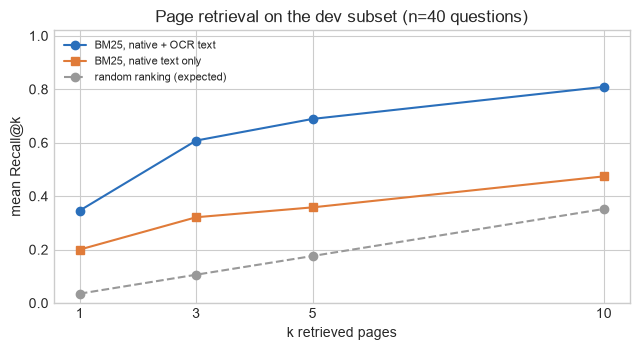

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ks = retrieval_summary.index
ax.plot(ks, retrieval_summary["BM25 Recall@k"], marker="o", color="#2A6FBB", label="BM25, native + OCR text")
ax.plot(ks, retrieval_summary["BM25 native-only Recall@k"], marker="s", color="#E07B39", label="BM25, native text only")
ax.plot(ks, retrieval_summary["random Recall@k"], marker="o", linestyle="--", color="#999999", label="random ranking (expected)")
ax.set(
    xlabel="k retrieved pages",
    ylabel="mean Recall@k",
    ylim=(0, 1.02),
    xticks=list(ks),
    title=f"Page retrieval on the dev subset (n={len(retrieval_population)} questions)",
)
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

In [18]:
gen_k = SETTINGS["generation_top_k"]
by_source = (
    retrieval_population.explode("evidence_sources")
    .groupby("evidence_sources")
    .agg(
        questions=("qid", "size"),
        native_recall=(f"native_recall@{gen_k}", "mean"),
        ocr_recall=(f"recall@{gen_k}", "mean"),
        median_evidence_native_words=("evidence_native_words", "median"),
    )
    .rename(columns={"native_recall": f"native-only Recall@{gen_k}", "ocr_recall": f"native + OCR Recall@{gen_k}"})
    .sort_values("questions", ascending=False)
    .round(3)
)
by_document = retrieval_population.groupby("doc_id").agg(
    questions=("qid", "size"),
    native_recall=(f"native_recall@{gen_k}", "mean"),
    ocr_recall=(f"recall@{gen_k}", "mean"),
    random_recall=(f"random_recall@{gen_k}", "mean"),
).round(3)
by_document["pages OCR'd"] = by_document.index.map(pages.groupby("doc_id")["ocr_used"].sum())
print(f"Recall@{gen_k} per document (native-only / native + OCR / random reference):")
display(by_document)
print("Per evidence source. A question with several sources is counted once per source; small groups are noisy.")
display(by_source)

Recall@5 per document (native-only / native + OCR / random reference):


,questions,native_recall,ocr_recall,random_recall,pages OCR'd
doc_id,,,,,
2210.02442v1.pdf,6,0.556,0.556,0.208,0
PG_2020.05.21_International-Cooperation-COVID_FINAL.pdf,7,0.857,0.857,0.192,1
bdf54dxa.pdf,5,0.000,0.500,0.093,53
earlybird-110722143746-phpapp02_95.pdf,7,0.000,0.440,0.122,41
germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf,11,0.091,0.788,0.217,23
watch_d.pdf,4,1.000,1.000,0.185,2


Per evidence source. A question with several sources is counted once per source; small groups are noisy.


,questions,native-only Recall@5,native + OCR Recall@5,median_evidence_native_words
evidence_sources,,,,
Figure,17,0.255,0.735,0.0
Chart,15,0.467,0.738,337.5
Pure-text (Plain-text),10,0.400,0.750,0.0
Table,7,0.143,0.571,0.0
Generalized-text (Layout),4,0.250,0.375,0.0


### Second page-convention check, using the retriever

BM25 never sees the annotations. If the benchmark's page numbers were shifted by one, the retriever's **top-1 page** would tend to sit next to the annotated page rather than on it. We count, over the retrieval population, how often the top-1 page equals an evidence page `p`, `p - 1` or `p + 1`. This is independent of the answer-string probe in Step 5 and uses all 40 questions instead of 17.

In [19]:
offset_labels = {-1: "top-1 page == p - 1", 0: "top-1 page == p (1-based)", 1: "top-1 page == p + 1 (0-based)"}
offset_counts = {
    label: int(sum(ranking[0] - offset in set(evidence) for evidence, ranking in zip(retrieval_population["evidence_pages"], retrieval_population["ranking"])))
    for offset, label in offset_labels.items()
}
display(pd.Series(offset_counts, name="questions").to_frame())
assert offset_counts["top-1 page == p (1-based)"] > max(offset_counts["top-1 page == p - 1"], offset_counts["top-1 page == p + 1 (0-based)"])

,questions
top-1 page == p - 1,5
top-1 page == p (1-based),16
top-1 page == p + 1 (0-based),5


### Interpretation

- **OCR is the largest effect in this notebook.** With identical BM25 settings, mean Recall@5 rises from 0.358 (native text only) to 0.689 (native + OCR). On the three image-only decks the native ranking is simply page order, and native-only Recall@5 there (0.000, 0.000, 0.091) falls *below* the random reference (0.093–0.217). Page order is worse than a random shuffle because evidence is rarely on the first pages.
- **BM25 is far above the random reference** at every k (Recall@5 0.689 versus 0.176 expected for random ranking), yet about 31% of evidence pages are still outside the top 5 — and the top 5 is all the LLM will see in Step 9.
- **Hit@5 (0.800) is higher than Recall@5 (0.689)** because cross-page questions often retrieve one evidence page but not all of them. A question such as "how many charts compare only US and Europe?" lists 10 evidence pages, which no top-5 list can cover; Recall@k counts this as a partial miss, while Hit@k hides it.
- **The second convention check agrees with Step 5:** the top-1 page coincides with an annotated page `p` far more often than with `p ± 1`.
- **By evidence source**, Table and Generalized-text questions are retrieved worst after OCR, but those groups contain 7 and 4 questions. This is a hypothesis to test on more documents, not a finding.
- **Clustered sample:** 40 questions come from only 6 documents, and per-document recall varies widely. A different seed could easily move the averages by 0.1.

## Step 8 — Answer-scoring rules, validated before any model is called

**The official protocol has three stages** (MMLongBench-Doc paper, §4.1, and `run_api.py`): (1) the model writes a free-form response; (2) GPT-4o extracts a short answer with a fixed few-shot prompt; (3) `eval_score(reference_answer, extracted_answer, reference_answer_format)` applies deterministic rules.

This notebook reproduces **stage 3** from `eval/eval_score.py` at commit `d73f0dc` of `github.com/mayubo2333/MMLongBench-Doc`, and replaces stages 1–2 with a structured short answer from the model (Step 9). Note that scoring uses the **reference** `answer_format`, not anything the model claims.

| `answer_format` | Rule |
|---|---|
| `Int` | exact equality after `int(float(prediction))` |
| `Float` | equal within 1% relative tolerance, also accepting ×100 or ÷100 (percentage vs fraction) |
| `Str`, `None` | lower-case; strip parenthesised text, surrounding quotes, `$`, `%`. Exact match for URLs, dates, phone-like numbers, e-mails, file names; otherwise ANLS with threshold 0.5 |
| `List` | same length required; elements cleaned and sorted; exact join for numeric or exact-type items, otherwise the **minimum** ANLS over pairs |

ANLS (average normalised Levenshtein similarity) gives partial credit to near-miss strings:

$$\text{ANLS}(g, p) = \begin{cases} 1 - \dfrac{\text{Lev}(g,p)}{\max(|g|,|p|)} & \text{if this is} > 0.5 \\ 0 & \text{otherwise.} \end{cases}$$

**Deviations from the official code (documented on purpose):** `ast.literal_eval` replaces `eval` for list strings, and a malformed list string is treated as one string instead of crashing; debug `print` calls are removed.

**Quirk kept on purpose:** the official `get_clean_string` tries to strip `mile`, `miles` and `million` suffixes but discards the result (`s.rstrip(...)` is never assigned). Those suffixes therefore stay, and we keep that behaviour so local scores follow official ones.

**Aggregates** (official definitions): *accuracy* is the mean score over all questions. *F1* uses recall = total score on answerable questions / number of answerable questions, and precision = total score on answerable questions / number of predictions that are not `"Not answerable"`. F1 therefore penalises both missed answers and invented answers to unanswerable questions.

In [20]:
def levenshtein_distance(s1, s2):
    if len(s1) > len(s2):
        s1, s2 = s2, s1
    distances = range(len(s1) + 1)
    for i2, c2 in enumerate(s2):
        new_distances = [i2 + 1]
        for i1, c1 in enumerate(s1):
            if c1 == c2:
                new_distances.append(distances[i1])
            else:
                new_distances.append(1 + min(distances[i1], distances[i1 + 1], new_distances[-1]))
        distances = new_distances
    return distances[-1]


def anls_compute(groundtruth, prediction, threshold=0.5):
    length = max(len(groundtruth.upper()), len(prediction.upper()))
    value = 0.0 if length == 0 else levenshtein_distance(groundtruth, prediction) / length
    anls = 1.0 - value
    return 0.0 if anls <= threshold else anls


def is_float_equal(reference, prediction, include_percentage=False, is_close=False):
    def get_precision(value):
        text = str(value)
        return len(text.split(".")[-1]) if "." in text else 3

    reference = float(str(reference).strip().rstrip("%").strip())
    try:
        prediction = float(str(prediction).strip().rstrip("%").strip())
    except (TypeError, ValueError):
        return False
    candidates = [reference / 100, reference, reference * 100] if include_percentage else [reference]
    for item in candidates:
        if is_close and isclose(item, prediction, rel_tol=0.01):
            return True
        precision = max(min(get_precision(prediction), get_precision(item)), 2)
        if round(prediction, precision) == round(item, precision):
            return True
    return False


def get_clean_string(s):
    s = str(s).lower().strip()
    # Official quirk: the code calls s.rstrip("mile") etc. without assigning the result,
    # so unit suffixes are NOT removed. Kept to reproduce official scores.
    s = re.sub(r"\s*\([^)]*\)", "", s).strip()  # remove parenthesised text
    s = re.sub(r"^['\"]|['\"]$", "", s).strip()  # remove surrounding quotes
    s = s.strip().lstrip("$").strip()
    s = s.strip().rstrip("%").strip()
    return s


EXACT_MATCH_PATTERNS = [
    r"\b\d+(-\d+|\s\d+)?\b",  # phone-like numbers
    r"\b\d{4}[-\s]\d{2}[-\s]\d{2}\b",  # YYYY-MM-DD
    r"\b\d{4}[-\s]\d{2}\b",  # YYYY-MM
    r"[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}",  # e-mail address
]


def is_exact_match(s):
    return (
        "https://" in s
        or s.endswith(".py")
        or s.endswith("ipynb")
        or s.startswith("page")
        or "a.m." in s
        or "p.m." in s
        or any(re.fullmatch(pattern, s) for pattern in EXACT_MATCH_PATTERNS)
    )


def isfloat(value):
    try:
        float(value)
        return True
    except (TypeError, ValueError):
        return False


def as_list(value):
    if isinstance(value, str) and value.startswith("["):
        try:
            value = ast.literal_eval(value)
        except (ValueError, SyntaxError):
            pass  # deviation: the official eval() would raise here
    return value if isinstance(value, list) else [value]


def eval_score(gt, pred, answer_type):
    if answer_type == "Int":
        try:
            gt, pred = int(gt), int(float(pred))
        except Exception:  # the official code uses a bare except
            pred = ""
        score = gt == pred
    elif answer_type == "Float":
        try:
            gt = float(get_clean_string(str(gt)))
            pred = float(get_clean_string(str(pred)))
        except Exception:
            pred = ""
        score = is_float_equal(gt, pred, include_percentage=True, is_close=True)
    elif answer_type in ("Str", "None"):
        gt, pred = get_clean_string(gt), get_clean_string(pred)
        score = gt == pred if is_exact_match(gt) else anls_compute(gt, pred)
    else:  # List
        gt, pred = as_list(gt), as_list(pred)
        if len(gt) != len(pred):
            score = 0.0
        else:
            gt = sorted(get_clean_string(item) for item in gt)
            pred = sorted(get_clean_string(item) for item in pred)
            if isfloat(gt[0]) or is_exact_match(gt[0]):
                score = "-".join(gt) == "-".join(pred)
            else:
                score = min(anls_compute(g, p) for g, p in zip(gt, pred))
    return float(score)

**Rule checks.** Each case targets one branch of the rules. The `expected` column was derived by hand by tracing the official `eval_score.py` source (commit `d73f0dc`) — it was **not** produced by executing the official file — so a mismatch would mean either a transcription error above or a mistake in the trace, and would need investigation.

In [21]:
SCORING_CASES = [
    # reference, prediction, format, expected, what the case checks
    ("Less well-off", "less well off", "Str", 1 - 1 / 13, "ANLS partial credit: 1 edit / 13 chars"),
    ("Pew Research Center", "Pew Research Centre", "Str", 1 - 2 / 19, "ANLS: transposition costs 2 edits"),
    ("Latinos", "Asian Americans", "Str", 0.0, "ANLS <= 0.5 is set to 0"),
    ("Not answerable", "Not answerable", "None", 1.0, "correct abstention"),
    ("Not answerable", "The report does not say", "None", 0.0, "abstention must use the exact phrase"),
    ("12", "12.0", "Int", 1.0, "Int: int(float(pred))"),
    ("12", "twelve", "Int", 0.0, "Int: unparseable prediction scores 0"),
    ("18.29%", "18.3", "Float", 1.0, "Float: 1% relative tolerance"),
    ("0.1", "10%", "Float", 1.0, "Float: fraction vs percentage (x100)"),
    ("51%", "49", "Float", 0.0, "Float: outside tolerance"),
    ("['Circle', 'Rectangle']", "['rectangle', 'circle']", "List", 1.0, "List: order and case ignored"),
    ("['White', '10%']", "['White']", "List", 0.0, "List: length mismatch scores 0"),
    ("['2014', '2016']", "['2016', '2014']", "List", 1.0, "List: numeric items use exact join"),
    ("https://www.example.com", "www.example.com", "Str", 0.0, "URL requires exact match"),
    ("2016-06", "2016-06", "Str", 1.0, "YYYY-MM requires exact match"),
    ("$1,200 (approx.)", "1,200", "Str", 1.0, "cleaning drops $ and parenthesised text"),
    ("5 miles", "5", "Str", 0.0, "official quirk: 'miles' is not stripped"),
]
case_table = pd.DataFrame(SCORING_CASES, columns=["reference", "prediction", "format", "expected", "checks"])
case_table["local"] = [eval_score(r, p, f) for r, p, f in zip(case_table["reference"], case_table["prediction"], case_table["format"])]
case_table["match"] = [isclose(local, expected, abs_tol=1e-9) for local, expected in zip(case_table["local"], case_table["expected"])]
display(case_table.round(4))
assert case_table["match"].all(), case_table[~case_table["match"]]

# A reference answer should score 1.0 against itself. Rows where it does not can never be
# answered correctly under the official rules, whatever the system predicts.
assert all(isfloat(get_clean_string(answer)) for answer in bench.loc[bench["answer_format"] == "Float", "answer"])
bench["self_score"] = [eval_score(row.answer, row.answer, row.answer_format) for row in bench.itertuples()]
unscorable = bench[bench["self_score"] < 1.0]
print(f"Rule checks passed. Reference answers that cannot score 1.0 against themselves: {len(unscorable)} of {len(bench)}")
display(unscorable[["qid", "doc_id", "answer", "answer_format", "self_score"]])
print("Of these, inside the dev subset:", sorted(set(unscorable["doc_id"]) & set(subset_documents)) or "none")
assert len(unscorable) <= 4, "new unscorable references appeared: inspect before trusting answer scores"

,reference,prediction,format,expected,checks,local,match
0,Less well-off,less well off,Str,0.9231,ANLS partial credit: 1 edit / 13 chars,0.9231,True
1,Pew Research Center,Pew Research Centre,Str,0.8947,ANLS: transposition costs 2 edits,0.8947,True
2,Latinos,Asian Americans,Str,0.0000,ANLS <= 0.5 is set to 0,0.0000,True
3,Not answerable,Not answerable,None,1.0000,correct abstention,1.0000,True
4,Not answerable,The report does not say,None,0.0000,abstention must use the exact phrase,0.0000,True
5,12,12.0,Int,1.0000,Int: int(float(pred)),1.0000,True
6,12,twelve,Int,0.0000,Int: unparseable prediction scores 0,0.0000,True
7,18.29%,18.3,Float,1.0000,Float: 1% relative tolerance,1.0000,True
8,0.1,10%,Float,1.0000,Float: fraction vs percentage (x100),1.0000,True
9,51%,49,Float,0.0000,Float: outside tolerance,0.0000,True


Rule checks passed. Reference answers that cannot score 1.0 against themselves: 4 of 1091


,qid,doc_id,answer,answer_format,self_score
210,mmlb-0210,05-03-18-political-release.pdf,21%,Int,0.0
733,mmlb-0733,germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf,14:04 CET,Int,0.0
735,mmlb-0735,germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf,yes,Int,0.0
980,mmlb-0980,2312.04350v3.pdf,GPT-4,Int,0.0


Of these, inside the dev subset: ['germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf']


In [22]:
def accuracy_and_f1(scored):
    """scored: DataFrame with columns answer, pred, score. Official MMLongBench-Doc definitions."""
    if scored.empty:
        return float("nan"), float("nan")
    accuracy = scored["score"].mean()
    answerable = scored["answer"] != "Not answerable"
    predicted_answer = scored["pred"] != "Not answerable"
    if answerable.sum() == 0 or predicted_answer.sum() == 0:
        return accuracy, 0.0  # the official code catches this ZeroDivisionError and returns F1 = 0
    recall = scored.loc[answerable, "score"].sum() / answerable.sum()
    precision = scored.loc[answerable, "score"].sum() / predicted_answer.sum()
    f1 = 2 * recall * precision / (recall + precision) if recall + precision > 0 else 0.0
    return accuracy, f1


# Formula check on a three-row toy table (not a result): one correct answer, one false abstention,
# one invented answer to an unanswerable question -> recall 1/2, precision 1/2, F1 1/2.
toy = pd.DataFrame({"answer": ["A", "B", "Not answerable"], "pred": ["A", "Not answerable", "C"], "score": [1.0, 0.0, 0.0]})
toy_accuracy, toy_f1 = accuracy_and_f1(toy)
assert isclose(toy_accuracy, 1 / 3) and isclose(toy_f1, 0.5)
print(f"Toy check: accuracy={toy_accuracy:.3f}, F1={toy_f1:.3f}")

Toy check: accuracy=0.333, F1=0.500


## Step 9 — Generate answers with an LLM (readiness-gated)

**Prompt design.**

- The evidence is the top-`generation_top_k` BM25 pages, in rank order, each labelled `[Page N]` with its **1-based** page number — the same convention as the benchmark, so citations can be compared with `evidence_pages` directly.
- Each page is truncated to `max_chars_per_page` characters to bound cost; pages without extractable text are marked as such instead of silently disappearing.
- The model returns JSON with `answer` and `cited_pages`. JSON avoids the official GPT-4o extraction stage, at the price of comparability (see Objective).
- The reference `answer_format` is **not** given to the model: format `None` means "unanswerable", so passing it would leak the answer to the abstention questions.
- `"Not answerable"` is requested verbatim because the scorer compares it as a string.

**Run modes.** API calls cost money, so they are opt-in through `VISUALDOC_GENERATION_MODE` (in `.env` or the shell):

| mode | API calls | answer metrics |
|---|---|---|
| `off` (default) | none | not computed |
| `smoke` | 1 test request | not computed |
| `pilot` | 1 test request + `pilot_size` fixed questions | on the pilot questions only |
| `full` | 1 test request + all subset questions | on the full subset |

In `pilot` and `full` modes, Step 13 then sends **one more request per answerable question** of the population (the oracle-page condition), only if this step completed.

**Why a smoke test.** An earlier run (`20261119T210333Z_84cb44ab`) sent all 57 requests and every one failed with the same `429 insufficient_quota / credit_balance_exhausted` error, and the failures were then scored 0 as if they were wrong answers. A single request with the real model, parameters and system prompt checks authentication, credit, model access, request parameters and the JSON reply format before any benchmark question is sent.

**Two kinds of failure, handled differently.**

- *Infrastructure failures* (the API call fails): classified from the exception class and the API error `code`. A credit-exhausted error is also an HTTP 429 `RateLimitError`, so the class alone would wrongly mark it as "retry later". Only rate limits, timeouts, connection errors and 5xx responses are retried (at most `max_attempts`, with 2 s, 4 s backoff), and the SDK's own silent retries are switched off (`max_retries=0`) so this loop controls the exact number of requests. The first question that still fails stops the batch. If any question in the population has no model response, **no answer metric is reported**.
- *Model failures* (the call succeeds but the reply is not valid JSON with an `answer` field): these are the model's behaviour, so they stay in the population and score 0, as in the official protocol, and are counted separately.

In [23]:
SYSTEM_PROMPT = """You answer questions about a single PDF document using only the page excerpts provided.
Each excerpt starts with a tag [Page N], where N is the 1-based page number in the PDF.

Return a JSON object with exactly these keys:
  "answer": the shortest complete answer. Use a number (integer or decimal) when the answer is a number,
            and a JSON list when several items are asked for. If the excerpts do not contain the answer,
            use exactly the string "Not answerable".
  "cited_pages": a list of the page numbers N whose excerpts support the answer ([] if "Not answerable").

Do not use knowledge outside the excerpts. Do not guess."""

page_text_raw = {(row.doc_id, row.page): row.text for row in pages.itertuples()}


def build_user_message(question, ranking, doc_id, top_k=SETTINGS["generation_top_k"], max_chars=SETTINGS["max_chars_per_page"]):
    blocks = []
    for page in ranking[:top_k]:
        text = page_text_raw[(doc_id, page)].strip()
        if len(text) > max_chars:
            text = text[:max_chars] + " [...truncated]"
        blocks.append(f"[Page {page}]\n{text or '(no extractable text on this page)'}")
    return f"Question: {question}\n\nPage excerpts:\n\n" + "\n\n".join(blocks)


PROMPT_HASH = hashlib.sha256((SETTINGS["prompt_version"] + SYSTEM_PROMPT).encode()).hexdigest()[:12]
example_message = build_user_message(example["question"], subset.loc[example.name, "ranking"], example["doc_id"])
message_lengths = [len(build_user_message(row.question, row.ranking, row.doc_id)) for row in subset.itertuples()]
print("Prompt hash:", PROMPT_HASH)
print(f"User-message length over the subset: median {np.median(message_lengths):,.0f} chars, max {max(message_lengths):,} chars")
print("-" * 80)
print(example_message[:900], "\n[... preview truncated ...]")

Prompt hash: f60729bf0b66
User-message length over the subset: median 9,092 chars, max 17,734 chars
--------------------------------------------------------------------------------
Question: How many more millions of dollars was the median exit valuation in the USA compared to Europe at the time of the presentation?

Page excerpts:

[Page 6]
At the same time,e    real performanceGg        shows
European VCa   | drivingee   the best exito multiplese
globally


  Exits over $ 100M
 2005 - Q1/2011





                                                             7.2

                                                                           Median Multiple
                                                                                             of Cash Invested                        45
                                                                                                                                                  Median Multiple
                                        

In [24]:
def generation_readiness():
    try:
        import openai  # noqa: F401

        has_package = True
    except ImportError:
        has_package = False
    checks = [
        ("provider is supported ('openai')", SETTINGS["model_provider"] == "openai", "set VISUALDOC_LLM_PROVIDER=openai"),
        ("model name chosen", bool(SETTINGS["model_name"]), "set VISUALDOC_LLM_MODEL in .env (open project decision)"),
        ("API key present", bool(os.getenv("OPENAI_API_KEY")), "set OPENAI_API_KEY in .env (the value is never printed)"),
        ("openai package installed", has_package, "pip install -e '.[llm]'"),
    ]
    return pd.DataFrame(checks, columns=["check", "ok", "how to fix"])


readiness = generation_readiness()
CREDENTIALS_READY = bool(readiness["ok"].all())
GENERATION_MODE = SETTINGS["generation_mode"]
GENERATION_READY = CREDENTIALS_READY and GENERATION_MODE != "off"
display(readiness)
print(f"Generation mode: {GENERATION_MODE!r} | configuration checks passed: {CREDENTIALS_READY} | GENERATION_READY = {GENERATION_READY}")
if GENERATION_MODE == "off":
    print("Mode 'off': no API call is made. Set VISUALDOC_GENERATION_MODE to smoke, pilot or full to call the model.")
elif not CREDENTIALS_READY:
    print("READINESS GATE: answer generation is skipped. No answer, citation or abstention metrics are reported for this run.")
print("Note: these checks are local. Only the smoke test below shows whether the API accepts the key, credit and model.")

,check,ok,how to fix
0,provider is supported ('openai'),True,set VISUALDOC_LLM_PROVIDER=openai
1,model name chosen,True,set VISUALDOC_LLM_MODEL in .env (open project decision)
2,API key present,True,set OPENAI_API_KEY in .env (the value is never printed)
3,openai package installed,True,pip install -e '.[llm]'


Generation mode: 'full' | configuration checks passed: True | GENERATION_READY = True
Note: these checks are local. Only the smoke test below shows whether the API accepts the key, credit and model.


The parser is tested on fixed strings first. These strings are **interface tests**, not model outputs, and never enter the results.

In [25]:
def parse_model_output(raw_text):
    """Return (prediction, cited_pages, error_message_or_None)."""
    try:
        payload = json.loads(raw_text)
        answer = payload["answer"]
        cited = [int(page) for page in payload.get("cited_pages", [])]
    except (json.JSONDecodeError, KeyError, TypeError, ValueError) as error:
        return "", [], f"unparseable model output: {error}"
    if isinstance(answer, str) and answer.strip().lower() == "not answerable":
        answer = "Not answerable"  # the F1 formula compares this exact string
    return answer, cited, None


assert parse_model_output('{"answer": "not answerable", "cited_pages": []}') == ("Not answerable", [], None)
assert parse_model_output('{"answer": 12, "cited_pages": ["4"]}') == (12, [4], None)
assert parse_model_output('{"answer": ["Circle", "Rectangle"], "cited_pages": [3, 7]}') == (["Circle", "Rectangle"], [3, 7], None)
assert parse_model_output('{"answer": 2.5}') == (2.5, [], None)  # missing cited_pages -> no citation, not an error
assert parse_model_output("The answer is 12 [Page 4]")[2].startswith("unparseable")  # prose instead of JSON
assert parse_model_output('{"cited_pages": [4]}')[2].startswith("unparseable")  # no answer key
assert parse_model_output('{"answer": "Europe IPO", "cited_pa')[2].startswith("unparseable")  # cut off by max tokens
assert parse_model_output('{"answer": 5, "cited_pages": ["page 4"]}')[2].startswith("unparseable")  # non-integer page
print("Parser interface checks passed.")

Parser interface checks passed.


### API error handling: classify, retry only what can recover, stop early

The decision table, applied by `classify_api_error` below. It reads the exception class and the structured `code`/`type` fields the API returns, never the free-text message:

| exception (HTTP status) | API `code` / `type` | category | retry? | effect on the batch |
|---|---|---|---|---|
| `RateLimitError` (429) | `insufficient_quota`, `credit_balance_exhausted`, … | `quota_or_billing` | no | stop — needs billing action |
| `RateLimitError` (429) | anything else | `rate_limit` | yes | stop if still failing after retries |
| `AuthenticationError` (401) | | `authentication` | no | stop — key invalid or revoked |
| `PermissionDeniedError` (403) | | `permission` | no | stop — project/region/model not allowed |
| `NotFoundError` (404) | e.g. `model_not_found` | `model_access` | no | stop — wrong model name or no access |
| `BadRequestError` (400) / 422 | e.g. `unsupported_parameter` | `invalid_request` | no | stop — the request itself is wrong |
| `APIConnectionError`, `APITimeoutError` | | `network` | yes | stop if still failing after retries |
| `InternalServerError` (5xx), 408, 409 | | `server` | yes | stop if still failing after retries |

Error messages are logged after replacing anything shaped like a key (`sk-…`) with `sk-<redacted>`. OpenAI's 401 messages echo part of the key.

In [26]:
import time

try:
    import openai
except ImportError:
    openai = None  # the readiness table above already reports the missing package

QUOTA_CODES = {"insufficient_quota", "credit_balance_exhausted", "billing_hard_limit_reached", "billing_not_active"}
SECRET_PATTERN = re.compile(r"sk-[A-Za-z0-9_\-\*]{4,}")


def sanitize(text, limit=300):
    return SECRET_PATTERN.sub("sk-<redacted>", str(text))[:limit]


def classify_api_error(error):
    """Return (category, retryable) for an exception raised by the OpenAI SDK."""
    if isinstance(error, openai.RateLimitError):
        if getattr(error, "code", None) in QUOTA_CODES or getattr(error, "type", None) in QUOTA_CODES:
            return "quota_or_billing", False  # same HTTP 429 as a rate limit, but waiting will not help
        return "rate_limit", True
    if isinstance(error, openai.AuthenticationError):
        return "authentication", False
    if isinstance(error, openai.PermissionDeniedError):
        return "permission", False
    if isinstance(error, openai.NotFoundError):
        return "model_access", False
    if isinstance(error, (openai.BadRequestError, openai.UnprocessableEntityError)):
        return "invalid_request", False
    if isinstance(error, openai.APIConnectionError):  # includes APITimeoutError
        return "network", True
    if isinstance(error, openai.InternalServerError) or (isinstance(error, openai.APIStatusError) and error.status_code in (408, 409)):
        return "server", True
    return "unexpected", False


def describe_api_error(error):
    category, retryable = classify_api_error(error)
    return {
        "category": category,
        "retryable": retryable,
        "exception": type(error).__name__,
        "status_code": getattr(error, "status_code", None),
        "code": getattr(error, "code", None),
        "type": getattr(error, "type", None),
        "message": sanitize(getattr(error, "message", error)),
        "request_id": getattr(error, "request_id", None),  # quote this to OpenAI support if needed
    }


def call_with_retries(create, request, max_attempts=SETTINGS["max_attempts"], sleep=time.sleep):
    """Call create(**request); retry only transient errors, waiting 2 s, 4 s, ...

    Returns (response or None, list of failed-attempt records, latency in seconds of the last attempt).
    Exceptions that are not OpenAI errors (bugs in this notebook) are not caught.
    """
    failures = []
    for attempt in range(1, max_attempts + 1):
        started = time.perf_counter()
        try:
            response = create(**request)
            return response, failures, round(time.perf_counter() - started, 3)
        except openai.OpenAIError as error:
            latency = round(time.perf_counter() - started, 3)
            failures.append(describe_api_error(error))
            if not failures[-1]["retryable"] or attempt == max_attempts:
                return None, failures, latency
            sleep(2**attempt)


def build_request(user_message):
    request = {
        "model": SETTINGS["model_name"],
        "messages": [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user_message}],
        "response_format": {"type": "json_object"},
        "max_completion_tokens": SETTINGS["max_output_tokens"],
    }
    if SETTINGS["temperature"] is not None:
        request["temperature"] = SETTINGS["temperature"]
    return request


def response_fields(response):
    usage = response.usage
    return {
        "raw_response": response.choices[0].message.content or "",
        "finish_reason": response.choices[0].finish_reason,
        "served_model": response.model,  # the exact model snapshot that answered, e.g. gpt-4o-mini-2024-07-18
        "prompt_tokens": usage.prompt_tokens if usage else None,
        "completion_tokens": usage.completion_tokens if usage else None,
    }


def generate_answers(question_rows, create, sleep=time.sleep, pages_for=None):
    """One record per question. The first question whose call still fails stops the batch;
    later questions are recorded as 'not_attempted' so the population stays fully accounted for.

    pages_for(row) -> the pages to supply. Default: the BM25 top-k (Step 9). Step 13 passes the oracle pages."""
    records, stop_reason = [], None
    for row in question_rows:
        supplied_pages = list(pages_for(row)) if pages_for else list(row.ranking[: SETTINGS["generation_top_k"]])
        record = {
            "qid": row.qid,
            "supplied_pages": supplied_pages,
            "requested_model": SETTINGS["model_name"],
            "status": "not_attempted",
            "pred": "",
            "cited_pages": [],
            "raw_response": None,
        }
        if stop_reason is None:
            request = build_request(build_user_message(row.question, supplied_pages, row.doc_id, top_k=len(supplied_pages)))
            response, failures, latency = call_with_retries(create, request, sleep=sleep)
            record.update(attempts=len(failures) + (response is not None), latency_s=latency, failed_attempts=failures)
            if response is None:
                record.update(status="api_error", error_category=failures[-1]["category"])
                stop_reason = f"{failures[-1]['category']} at {row.qid} after {len(failures)} attempt(s)"
            else:
                record.update(response_fields(response))
                pred, cited, parse_error = parse_model_output(record["raw_response"])
                record.update(pred=pred, cited_pages=cited, parse_error=parse_error, status="ok" if parse_error is None else "parse_error")
        records.append(record)
    return records, stop_reason


def generation_outcome(records, population_qids):
    """Answer metrics are valid only if every population question received a model response."""
    status = pd.Series({r["qid"]: r["status"] for r in records}, dtype=object).reindex(population_qids).fillna("not_attempted")
    return bool(status.isin(["ok", "parse_error"]).all()), status.value_counts().to_dict()


print("Error classification, retry and batch helpers defined." if openai else "openai is not installed: generation helpers are unusable.")

Error classification, retry and batch helpers defined.


**Offline tests with mocked API responses.** No request leaves the machine here. The mocks are real SDK exception and `ChatCompletion` objects built from fixed bodies; the credit-exhausted body is copied from the failed run's `errors.jsonl`. They test the plumbing and **never enter the results**.

In [27]:
if openai is None:
    print("Skipped: openai is not installed, so the SDK exception classes cannot be mocked.")
else:
    import httpx
    from openai.types.chat import ChatCompletion

    MOCK_REQUEST = httpx.Request("POST", "https://api.openai.com/v1/chat/completions")

    def mock_status_error(cls, status, body):
        response = httpx.Response(status, request=MOCK_REQUEST, headers={"x-request-id": "req_mock"})
        return cls(f"Error code: {status} - {body}", response=response, body=body)

    def mock_completion(content, finish_reason="stop"):
        return ChatCompletion.model_validate(
            {
                "id": "chatcmpl-mock", "object": "chat.completion", "created": 0, "model": "mock-model-snapshot",
                "choices": [{"index": 0, "finish_reason": finish_reason, "message": {"role": "assistant", "content": content}}],
                "usage": {"prompt_tokens": 100, "completion_tokens": 10, "total_tokens": 110},
            }
        )

    def scripted(*outcomes):
        """A stand-in for client.chat.completions.create that replays outcomes in order and records each request."""
        calls = []

        def create(**request):
            calls.append(request)
            outcome = outcomes[min(len(calls), len(outcomes)) - 1]
            if isinstance(outcome, Exception):
                raise outcome
            return outcome

        return create, calls

    QUOTA_BODY = {  # verbatim from experiments/runs/mmlongbench_doc/20261119T210333Z_84cb44ab/errors.jsonl
        "message": "You have no credits remaining. Add credits to continue using the API at https://platform.openai.com/settings/organization/billing/.",
        "type": "insufficient_quota", "param": None, "code": "credit_balance_exhausted",
    }
    quota_error = mock_status_error(openai.RateLimitError, 429, QUOTA_BODY)
    cases = [
        ("credits exhausted (real body)", quota_error, "quota_or_billing", False),
        ("ordinary rate limit", mock_status_error(openai.RateLimitError, 429, {"message": "Rate limit reached for requests", "type": "requests", "param": None, "code": "rate_limit_exceeded"}), "rate_limit", True),
        ("invalid key", mock_status_error(openai.AuthenticationError, 401, {"message": "Incorrect API key provided: sk-proj-abcd****wxyz.", "type": "invalid_request_error", "param": None, "code": "invalid_api_key"}), "authentication", False),
        ("project lacks permission", mock_status_error(openai.PermissionDeniedError, 403, {"message": "Project does not have access to this model.", "type": "invalid_request_error", "param": None, "code": None}), "permission", False),
        ("model not available", mock_status_error(openai.NotFoundError, 404, {"message": "The model `gpt-x` does not exist or you do not have access to it.", "type": "invalid_request_error", "param": None, "code": "model_not_found"}), "model_access", False),
        ("unsupported parameter", mock_status_error(openai.BadRequestError, 400, {"message": "Unsupported parameter: 'temperature'.", "type": "invalid_request_error", "param": "temperature", "code": "unsupported_parameter"}), "invalid_request", False),
        ("timeout", openai.APITimeoutError(request=MOCK_REQUEST), "network", True),
        ("connection reset", openai.APIConnectionError(request=MOCK_REQUEST), "network", True),
        ("server error", mock_status_error(openai.InternalServerError, 500, {"message": "The server had an error.", "type": "server_error", "param": None, "code": None}), "server", True),
    ]
    case_rows = []
    for name, error, expected_category, expected_retry in cases:
        record = describe_api_error(error)
        case_rows.append({"case": name, "exception": record["exception"], "status": record["status_code"], "code": record["code"],
                          "category": record["category"], "retry": record["retryable"],
                          "ok": (record["category"], record["retryable"]) == (expected_category, expected_retry)})
    error_case_table = pd.DataFrame(case_rows)
    display(error_case_table)
    assert error_case_table["ok"].all()
    assert "abcd" not in describe_api_error(cases[2][1])["message"], "key fragment leaked into the log"

    # A. Credits exhausted: exactly one request, no waiting (the SDK default would have sent 3).
    waits = []
    create, calls = scripted(quota_error)
    response, failures, _ = call_with_retries(create, {"model": "m"}, sleep=waits.append)
    assert response is None and len(calls) == 1 and waits == [] and failures[0]["category"] == "quota_or_billing"

    # B. A transient rate limit followed by success: one retry after 2 s.
    waits = []
    create, calls = scripted(cases[1][1], mock_completion('{"answer": 1}'))
    response, failures, _ = call_with_retries(create, {"model": "m"}, sleep=waits.append)
    assert response is not None and len(calls) == 2 and waits == [2]

    # C. A persistent server error: bounded at max_attempts requests, waits 2 s then 4 s.
    waits = []
    create, calls = scripted(cases[8][1])
    response, failures, _ = call_with_retries(create, {"model": "m"}, sleep=waits.append)
    assert response is None and len(calls) == SETTINGS["max_attempts"] == 3 and waits == [2, 4]

    # D. A bug in our own code is not mistaken for an API failure: it propagates.
    def broken_create(**request):
        raise KeyError("bug")

    try:
        call_with_retries(broken_create, {"model": "m"}, sleep=waits.append)
        raise AssertionError("a non-API exception was swallowed")
    except KeyError:
        pass

    test_rows = list(subset.head(4).itertuples())
    test_qids = [row.qid for row in test_rows]

    # E. Batch stop: the failed run's error on question 1 -> 1 request in total, the rest not attempted, metrics gated.
    create, calls = scripted(quota_error)
    records, stop_reason = generate_answers(test_rows, create, sleep=lambda seconds: None)
    assert len(calls) == 1 and [r["status"] for r in records] == ["api_error", "not_attempted", "not_attempted", "not_attempted"]
    assert stop_reason.startswith("quota_or_billing") and generation_outcome(records, test_qids)[0] is False

    # F. Successful replies: JSON answer and citations parsed; model, tokens and latency recorded.
    #    A truncated reply is a model failure (parse_error, scored 0), not an infrastructure failure.
    create, calls = scripted(
        mock_completion('{"answer": 63, "cited_pages": [6]}'),
        mock_completion('{"answer": "not answerable", "cited_pages": []}'),
        mock_completion('{"answer": "Europe IPO", "cited_pa', finish_reason="length"),
    )
    records, stop_reason = generate_answers(test_rows[:3], create)
    assert stop_reason is None and [r["status"] for r in records] == ["ok", "ok", "parse_error"]
    assert (records[0]["pred"], records[0]["cited_pages"]) == (63, [6]) and records[1]["pred"] == "Not answerable"
    assert records[0]["served_model"] == "mock-model-snapshot" and records[0]["prompt_tokens"] == 100 and records[0]["latency_s"] >= 0
    assert records[2]["finish_reason"] == "length" and records[2]["pred"] == ""
    assert generation_outcome(records, test_qids[:3]) == (True, {"ok": 2, "parse_error": 1})

    # G. Denominator: a population question with no record at all counts as not attempted, so metrics stay gated.
    complete, counts = generation_outcome(records, test_qids)
    assert complete is False and counts["not_attempted"] == 1

    # H. The request carries the configured model and parameters.
    assert calls[0]["model"] == SETTINGS["model_name"] and calls[0]["response_format"] == {"type": "json_object"}
    assert calls[0]["max_completion_tokens"] == SETTINGS["max_output_tokens"] and calls[0]["messages"][0]["content"] == SYSTEM_PROMPT

    # I. pages_for replaces the BM25 top-k: exactly the given pages are supplied, labelled and recorded.
    create, calls = scripted(mock_completion('{"answer": 1, "cited_pages": [2]}'))
    records, _ = generate_answers(test_rows[:1], create, pages_for=lambda row: [2, 9])
    user_message = calls[0]["messages"][1]["content"]
    assert records[0]["supplied_pages"] == [2, 9] and user_message.count("[Page ") == 2
    assert "[Page 2]" in user_message and "[Page 9]" in user_message

    # J. Without pages_for, the request is byte-identical to the Step 9 prompt for the BM25 top-k.
    create, calls = scripted(mock_completion('{"answer": 1}'))
    generate_answers(test_rows[:1], create)
    row = test_rows[0]
    assert calls[0]["messages"][1]["content"] == build_user_message(row.question, row.ranking, row.doc_id)

    print("Mocked API tests passed: classification, bounded retries, batch stop, parsing, usage logging, metric gating, page selection.")

,case,exception,status,code,category,retry,ok
0,credits exhausted (real body),RateLimitError,429.0,credit_balance_exhausted,quota_or_billing,False,True
1,ordinary rate limit,RateLimitError,429.0,rate_limit_exceeded,rate_limit,True,True
2,invalid key,AuthenticationError,401.0,invalid_api_key,authentication,False,True
3,project lacks permission,PermissionDeniedError,403.0,NaN,permission,False,True
4,model not available,NotFoundError,404.0,model_not_found,model_access,False,True
5,unsupported parameter,BadRequestError,400.0,unsupported_parameter,invalid_request,False,True
6,timeout,APITimeoutError,NaN,NaN,network,True,True
7,connection reset,APIConnectionError,NaN,NaN,network,True,True
8,server error,InternalServerError,500.0,NaN,server,True,True


Mocked API tests passed: classification, bounded retries, batch stop, parsing, usage logging, metric gating, page selection.


### Answer population: pilot or full subset

The pilot is a fixed, seeded sample of `pilot_size` questions from the 57-question subset: `pilot_size − 1` answerable questions and 1 unanswerable one, so every answer metric (including correct abstention) is defined. It uses its own random generator, so the document subset and the retrieval metrics do not change.

In pilot mode, answer metrics are computed over **the pilot questions only**. `answer_population` is the denominator, never the 57-question subset. Five questions validate the pipeline end to end. They are too few to estimate performance.

In [28]:
pilot_rng = np.random.default_rng(SETTINGS["seed"])  # separate generator: the document subset is unaffected
answerable_qids = sorted(subset.loc[subset["answerable"], "qid"])
unanswerable_qids = sorted(subset.loc[~subset["answerable"], "qid"])
pilot_qids = sorted(
    pilot_rng.choice(answerable_qids, size=SETTINGS["pilot_size"] - 1, replace=False).tolist()
    + pilot_rng.choice(unanswerable_qids, size=1, replace=False).tolist()
)
pilot = subset[subset["qid"].isin(pilot_qids)]
answer_population = pilot if GENERATION_MODE == "pilot" else subset

pilot_view = pilot.assign(
    evidence_in_top_k=[bool(set(e) & set(r[: SETTINGS["generation_top_k"]])) if a else None for e, r, a in zip(pilot["evidence_pages"], pilot["ranking"], pilot["answerable"])]
)
display(pilot_view[["qid", "doc_id", "answer_format", "answerable", "evidence_pages", "evidence_in_top_k"]])
print(f"Answer population for mode {GENERATION_MODE!r}: {len(answer_population)} questions "
      f"({int((~answer_population['answerable']).sum())} unanswerable)")

,qid,doc_id,answer_format,answerable,evidence_pages,evidence_in_top_k
3,mmlb-0036,earlybird-110722143746-phpapp02_95.pdf,Int,True,"[14, 19, 20, 33, 37]",False
23,mmlb-0355,PG_2020.05.21_International-Cooperation-COVID_FINAL.pdf,Str,True,[19],True
36,mmlb-0731,germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf,List,True,"[7, 8]",True
39,mmlb-0734,germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf,None,False,[],None
41,mmlb-0736,germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf,Int,True,[14],True


Answer population for mode 'full': 57 questions (17 unanswerable)


In [29]:
# Smoke test: one real request with the configured model, parameters and system prompt, on a fixed
# one-page excerpt. It is an interface check (expected reply: 2019, cited page 1); it never enters the results.
SMOKE_USER_MESSAGE = "Question: In which year was the report published?\n\nPage excerpts:\n\n[Page 1]\nThis report was published in 2019 by the research team."
EXTERNAL_ACTION = {
    "quota_or_billing": "Add credits or raise the budget limit for the organization/project that owns this key: "
    "https://platform.openai.com/settings/organization/billing/ . No code change can fix this.",
    "authentication": "The key was rejected: create a new key at https://platform.openai.com/api-keys and replace OPENAI_API_KEY in .env.",
    "permission": "The key's project may not use this model: allow it in the project's settings, or use a key from a project that can.",
    "model_access": "Check VISUALDOC_LLM_MODEL (spelling) and that the key's project has access to that model.",
    "invalid_request": "A request parameter is not accepted for this model: read `param` and `message` below.",
    "rate_limit": "Transient: retry later, or lower the request rate.",
    "network": "Transient: check the connection and retry.",
    "server": "Transient: OpenAI server error, retry later.",
    "unexpected": "Unclassified error: inspect `exception` and `message` below.",
}

smoke_record = {"status": "not run"}
if GENERATION_READY:
    from openai import OpenAI

    # max_retries=0: the SDK would otherwise silently retry every 429, including 'no credits' errors.
    client = OpenAI(max_retries=0, timeout=SETTINGS["request_timeout_s"])
    response, failures, latency = call_with_retries(client.chat.completions.create, build_request(SMOKE_USER_MESSAGE))
    smoke_record = {"requested_model": SETTINGS["model_name"], "attempts": len(failures) + (response is not None), "latency_s": latency, "failed_attempts": failures}
    if response is None:
        smoke_record.update(status="api_error", error_category=failures[-1]["category"])
    else:
        smoke_record.update(response_fields(response))
        pred, cited, parse_error = parse_model_output(smoke_record["raw_response"])
        smoke_record.update(pred=pred, cited_pages=cited, parse_error=parse_error, status="ok" if parse_error is None else "parse_error")
SMOKE_OK = smoke_record["status"] == "ok"

print("Smoke test:", smoke_record["status"])
display(pd.Series({k: v for k, v in smoke_record.items() if k not in ("failed_attempts", "raw_response")}, dtype=object).to_frame("value"))
if smoke_record.get("failed_attempts"):
    display(pd.DataFrame(smoke_record["failed_attempts"]))
if smoke_record["status"] == "api_error":
    print("REQUIRED ACTION:", EXTERNAL_ACTION[smoke_record["error_category"]])
    print("No benchmark question will be sent in this run.")

Smoke test: ok


,value
requested_model,gpt-4o-mini
attempts,1
latency_s,0.704
finish_reason,stop
served_model,gpt-4o-mini-2024-07-18
prompt_tokens,181
completion_tokens,19
pred,2019
cited_pages,[1]
parse_error,None


In [30]:
prediction_rows, STOP_REASON = [], None
if GENERATION_READY and SMOKE_OK and GENERATION_MODE in ("pilot", "full"):
    prediction_rows, STOP_REASON = generate_answers(answer_population.itertuples(), client.chat.completions.create)

GENERATION_COMPLETE, status_counts = generation_outcome(prediction_rows, answer_population["qid"].tolist())
if GENERATION_MODE == "off":
    GENERATION_STATUS = "skipped: generation mode 'off' (no API call)"
elif not CREDENTIALS_READY:
    GENERATION_STATUS = "skipped (failed checks: " + "; ".join(readiness.loc[~readiness["ok"], "check"]) + ")"
elif not SMOKE_OK:
    reason = smoke_record.get("error_category") or smoke_record["status"]
    GENERATION_STATUS = f"stopped at smoke test ({reason}): no benchmark question sent"
elif GENERATION_MODE == "smoke":
    GENERATION_STATUS = "smoke test passed: no benchmark question sent (mode 'smoke')"
elif GENERATION_COMPLETE:
    GENERATION_STATUS = f"complete: {GENERATION_MODE} population, {len(answer_population)} questions"
else:
    GENERATION_STATUS = f"incomplete: stopped by {STOP_REASON}; answer metrics not reported"
print("Generation status:", GENERATION_STATUS)

predictions = pd.DataFrame(prediction_rows)
if prediction_rows:
    print("Question status:", status_counts)
    display(
        predictions.reindex(columns=["qid", "status", "attempts", "served_model", "finish_reason", "prompt_tokens", "completion_tokens", "latency_s", "pred", "cited_pages"])
    )
    print(f"Tokens: {predictions['prompt_tokens'].sum():,.0f} prompt + {predictions['completion_tokens'].sum():,.0f} completion "
          f"| median latency {predictions['latency_s'].median():.2f} s")

# Sanitized error log: every failed attempt (smoke test included) and every unparseable reply.
error_rows = [{"qid": "smoke_test", "stage": "api_call", **failure} for failure in smoke_record.get("failed_attempts", [])]
if smoke_record["status"] == "parse_error":
    error_rows.append({"qid": "smoke_test", "stage": "parse", "message": smoke_record["parse_error"], "raw": smoke_record["raw_response"][:500]})
for record in prediction_rows:
    error_rows += [{"qid": record["qid"], "stage": "api_call", **failure} for failure in record.get("failed_attempts", [])]
    if record["status"] == "parse_error":
        error_rows.append({"qid": record["qid"], "stage": "parse", "message": record["parse_error"], "raw": record["raw_response"][:500]})
errors = pd.DataFrame(error_rows)

Generation status: complete: full population, 57 questions
Question status: {'ok': 57}


,qid,status,attempts,served_model,finish_reason,prompt_tokens,completion_tokens,latency_s,pred,cited_pages
0,mmlb-0033,ok,1,gpt-4o-mini-2024-07-18,stop,1212,18,0.735,63,[6]
1,mmlb-0034,ok,1,gpt-4o-mini-2024-07-18,stop,1001,18,0.806,Not answerable,[]
2,mmlb-0035,ok,1,gpt-4o-mini-2024-07-18,stop,1084,18,3.381,Not answerable,[]
3,mmlb-0036,ok,1,gpt-4o-mini-2024-07-18,stop,1062,16,0.602,0,[]
4,mmlb-0037,ok,1,gpt-4o-mini-2024-07-18,stop,1084,29,0.904,"[Deutsche Bank Private Equity, Earlybird]","[19, 30]"
5,mmlb-0038,ok,1,gpt-4o-mini-2024-07-18,stop,1080,18,0.815,Not answerable,[]
6,mmlb-0039,ok,1,gpt-4o-mini-2024-07-18,stop,742,18,0.608,1,[17]
7,mmlb-0040,ok,1,gpt-4o-mini-2024-07-18,stop,796,18,1.158,Not answerable,[]
8,mmlb-0041,ok,1,gpt-4o-mini-2024-07-18,stop,901,18,0.688,350,[26]
9,mmlb-0094,ok,1,gpt-4o-mini-2024-07-18,stop,2026,30,0.814,5,"[15, 13, 14]"


Tokens: 107,988 prompt + 1,191 completion | median latency 0.77 s


## Step 10 — Citation checks and answer scoring

- **Citation validity** (mechanical): every cited page was among the pages supplied to the model. An invalid citation is an invented page number.
- **Citation correctness** (answerable questions only): at least one cited page is an annotated evidence page.
- **Abstention:** on unanswerable questions, the prediction is exactly `"Not answerable"`; on answerable ones, saying `"Not answerable"` is a false abstention (often caused by a retrieval miss).

In [31]:
if predictions.empty:
    scored = pd.DataFrame()
    answer_metrics = None
    print("No model predictions in this run: answer, citation and abstention metrics are NOT computed.")
elif not GENERATION_COMPLETE:
    # A question without a model response is an infrastructure failure, not a wrong answer: scoring it 0
    # would report the API outage as model performance. No partial metric is reported either.
    scored = pd.DataFrame()
    answer_metrics = None
    print(f"Generation incomplete ({status_counts}): answer, citation and abstention metrics are NOT computed.")
else:
    # Denominator = the answer population (pilot or full subset), one row per question.
    scored = answer_population.merge(predictions, on="qid", how="inner", validate="one_to_one")
    assert len(scored) == len(answer_population)
    scored["score"] = [eval_score(r.answer, r.pred, r.answer_format) for r in scored.itertuples()]
    scored["citations_valid"] = [set(c) <= set(s) for c, s in zip(scored["cited_pages"], scored["supplied_pages"])]
    scored["cites_evidence"] = [
        bool(set(c) & set(e)) if answerable else np.nan
        for c, e, answerable in zip(scored["cited_pages"], scored["evidence_pages"], scored["answerable"])
    ]
    scored["predicted_unanswerable"] = scored["pred"].map(lambda pred: pred == "Not answerable")
    accuracy, f1 = accuracy_and_f1(scored)
    answerable_rows = scored[scored["answerable"]]
    unanswerable_rows = scored[~scored["answerable"]]
    answer_metrics = {
        "questions": len(scored),
        "accuracy (local rules)": accuracy,
        "F1 (official definition)": f1,
        "accuracy on answerable": answerable_rows["score"].mean(),
        "accuracy on unanswerable (correct abstention)": unanswerable_rows["score"].mean(),
        "false abstention rate on answerable": answerable_rows["predicted_unanswerable"].mean(),
        "citation validity": scored["citations_valid"].mean(),
        "cites an evidence page (answerable)": answerable_rows["cites_evidence"].astype(float).mean(),
        "unparseable replies (scored 0)": int((scored["status"] == "parse_error").sum()),
    }
    print(f"Answer population: {GENERATION_MODE} ({len(scored)} questions)")
    display(pd.Series(answer_metrics, name="value").to_frame().round(3))

Answer population: full (57 questions)


,value
questions,57.000
accuracy (local rules),0.263
F1 (official definition),0.165
accuracy on answerable,0.175
accuracy on unanswerable (correct abstention),0.471
false abstention rate on answerable,0.100
citation validity,1.000
cites an evidence page (answerable),0.650
unparseable replies (scored 0),0.000


## Step 11 — Save predictions, settings, errors and results

Each run gets its own folder under `experiments/runs/mmlongbench_doc/` (git-ignored: raw model output can be large and should not be published by accident). The folder name combines a UTC timestamp with a hash of the settings, subset and prompt, so two runs with identical configuration share the hash suffix.

In [32]:
def to_jsonable(value):
    return value.item() if hasattr(value, "item") else str(value)


configuration = {**SETTINGS, "subset_documents": subset_documents, "system_prompt": SYSTEM_PROMPT}
configuration_hash = hashlib.sha256(json.dumps(configuration, sort_keys=True, default=to_jsonable).encode()).hexdigest()[:8]
run_id = f"{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}_{configuration_hash}"
run_dir = RUNS_DIR / run_id
run_dir.mkdir(parents=True, exist_ok=True)

settings_record = {
    **configuration,
    "run_id": run_id,
    "configuration_hash": configuration_hash,
    "prompt_hash": PROMPT_HASH,
    "subset_qids": subset["qid"].tolist(),
    "pilot_qids": pilot_qids,
    "answer_population_qids": answer_population["qid"].tolist(),
    "generation_status": GENERATION_STATUS,
    "environment": {
        "python": sys.version.split()[0],
        "pymupdf": pymupdf.VersionBind,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "openai": getattr(openai, "__version__", None),
        "os": platform.system(),
    },
}
(run_dir / "settings.json").write_text(json.dumps(settings_record, indent=2, default=to_jsonable))

retrieval_columns = ["qid", "doc_id", "answer_format", "evidence_pages", "evidence_sources", "page_count", "evidence_native_words", "ranking", "ranking_native"]
retrieval_columns += [c for c in retrieval_population.columns if c.startswith(("recall@", "hit@", "native_", "random_"))]
retrieval_population.assign(
    ranking=lambda f: f["ranking"].map(lambda r: r[:max_k]),
    ranking_native=lambda f: f["ranking_native"].map(lambda r: r[:max_k]),
)[retrieval_columns].to_csv(
    run_dir / "retrieval_per_question.csv", index=False
)
retrieval_summary.to_csv(run_dir / "retrieval_summary.csv")

(run_dir / "smoke_test.json").write_text(json.dumps(smoke_record, indent=2, default=to_jsonable))
with open(run_dir / "predictions.jsonl", "w") as handle:
    for record in prediction_rows:
        handle.write(json.dumps(record, default=to_jsonable) + "\n")
with open(run_dir / "errors.jsonl", "w") as handle:
    for record in error_rows:
        handle.write(json.dumps(record, default=to_jsonable) + "\n")
generation_record = {
    "mode": GENERATION_MODE,
    "answer_population_size": len(answer_population),
    "smoke_test": smoke_record["status"],
    "question_status": status_counts if prediction_rows else {},
    "requested_model": SETTINGS["model_name"],
    "served_models": sorted(predictions["served_model"].dropna().unique().tolist()) if "served_model" in predictions else [],
    "prompt_tokens": int(predictions["prompt_tokens"].sum()) if "prompt_tokens" in predictions else 0,
    "completion_tokens": int(predictions["completion_tokens"].sum()) if "completion_tokens" in predictions else 0,
}
(run_dir / "answer_summary.json").write_text(
    json.dumps({"generation_status": GENERATION_STATUS, "generation": generation_record, "metrics": answer_metrics}, indent=2, default=to_jsonable)
)
if not scored.empty:
    scored.drop(columns=["raw_response", "failed_attempts"]).to_csv(run_dir / "scored_predictions.csv", index=False)

pd.DataFrame(
    [{"file": path.name, "bytes": path.stat().st_size} for path in sorted(run_dir.iterdir())]
).assign(folder=str(run_dir.relative_to(PROJECT_ROOT)))

,file,bytes,folder
0,answer_summary.json,796,experiments/runs/mmlongbench_doc/20261119T220858Z_a351a532
1,errors.jsonl,0,experiments/runs/mmlongbench_doc/20261119T220858Z_a351a532
2,predictions.jsonl,24154,experiments/runs/mmlongbench_doc/20261119T220858Z_a351a532
3,retrieval_per_question.csv,16184,experiments/runs/mmlongbench_doc/20261119T220858Z_a351a532
4,retrieval_summary.csv,203,experiments/runs/mmlongbench_doc/20261119T220858Z_a351a532
5,scored_predictions.csv,33606,experiments/runs/mmlongbench_doc/20261119T220858Z_a351a532
6,settings.json,4462,experiments/runs/mmlongbench_doc/20261119T220858Z_a351a532
7,smoke_test.json,382,experiments/runs/mmlongbench_doc/20261119T220858Z_a351a532


## Step 12 — Results

One compact table for the run, then concrete successes and failures. Retrieval numbers are real measurements on this subset; answer metrics appear only if the generation gate was open.

In [33]:
results_rows = [
    ("documents / questions", f"{len(subset_documents)} / {len(subset)} ({int((~subset['answerable']).sum())} unanswerable)"),
    ("retrieval population", f"{len(retrieval_population)} answerable questions with evidence pages"),
]
for k in SETTINGS["k_values"]:
    results_rows.append(
        (f"BM25 Recall@{k}", f"{retrieval_summary.loc[k, 'BM25 Recall@k']:.3f}  (random {retrieval_summary.loc[k, 'random Recall@k']:.3f})")
    )
results_rows.append((f"BM25 native-only Recall@{gen_k}", f"{retrieval_summary.loc[gen_k, 'BM25 native-only Recall@k']:.3f}"))
results_rows.append((f"BM25 Hit@{gen_k}", f"{retrieval_summary.loc[gen_k, 'BM25 Hit@k']:.3f}  (random {retrieval_summary.loc[gen_k, 'random Hit@k']:.3f})"))
results_rows.append(("generation status", GENERATION_STATUS))
results_rows.append(("answer population", f"{GENERATION_MODE}: {len(answer_population)} questions" if answer_metrics else "none"))
answer_metric_names = [
    "accuracy (local rules)",
    "F1 (official definition)",
    "accuracy on unanswerable (correct abstention)",
    "citation validity",
    "cites an evidence page (answerable)",
]
for name in answer_metric_names:
    value = "not reported (see generation status)" if answer_metrics is None else f"{answer_metrics[name]:.3f}"
    results_rows.append((name, value))
served = sorted(predictions["served_model"].dropna().unique()) if "served_model" in predictions else []
results_rows.append(("model requested / served", f"{SETTINGS['model_name'] or 'none configured'} / {', '.join(served) or 'no response'}"))
results_rows.append(("run folder", str(run_dir.relative_to(PROJECT_ROOT))))
results_table = pd.DataFrame(results_rows, columns=["metric", "value"])
print("BM25 rows use native text + OCR fallback unless marked native-only.")
results_table

BM25 rows use native text + OCR fallback unless marked native-only.


,metric,value
0,documents / questions,6 / 57 (17 unanswerable)
1,retrieval population,40 answerable questions with evidence pages
2,BM25 Recall@1,0.346 (random 0.035)
3,BM25 Recall@3,0.608 (random 0.106)
4,BM25 Recall@5,0.689 (random 0.176)
5,BM25 Recall@10,0.809 (random 0.352)
6,BM25 native-only Recall@5,0.358
7,BM25 Hit@5,0.800 (random 0.293)
8,generation status,"complete: full population, 57 questions"
9,answer population,full: 57 questions


In [34]:
example_columns = ["qid", "question", "evidence_pages", "evidence_sources", "top_pages", "evidence_native_words"]
examples_view = retrieval_population.assign(top_pages=lambda frame: frame["ranking"].map(lambda r: r[:gen_k]))

print(f"Retrieval successes — every evidence page is in the top {gen_k}:")
display(examples_view[examples_view[f"recall@{gen_k}"] == 1][example_columns].head(3))
print(f"Retrieval failures — no evidence page in the top {gen_k}:")
display(examples_view[examples_view[f"hit@{gen_k}"] == 0][example_columns].head(4))

if not scored.empty:
    answer_columns = ["qid", "question", "answer", "pred", "answer_format", "score", "cited_pages", "evidence_pages"]
    print("Answer successes:")
    display(scored[scored["score"] >= 0.99][answer_columns].head(3))
    print("Answer failures:")
    display(scored[scored["score"] < 0.5][answer_columns].head(4))

Retrieval successes — every evidence page is in the top 5:


,qid,question,evidence_pages,evidence_sources,top_pages,evidence_native_words
0,mmlb-0033,How many more millions of dollars was the median exit valuation in the USA c...,[6],"[Chart, Table]","[6, 27, 2, 26, 30]",0.0
1,mmlb-0034,"Which was greater at the time of the presentation, Europe IPO index value or...",[11],[Chart],"[11, 6, 26, 2, 27]",0.0
8,mmlb-0041,"On the chart showing average exit cap, there is one point that US, Europe, a...",[26],[Chart],"[7, 26, 6, 27, 33]",0.0


Retrieval failures — no evidence page in the top 5:


,qid,question,evidence_pages,evidence_sources,top_pages,evidence_native_words
3,mmlb-0036,How many human quotes are provided with source in this document?,"[14, 19, 20, 33, 37]","[Figure, Generalized-text (Layout)]","[38, 30, 2, 5, 7]",0.0
4,mmlb-0037,Which two magazines' opinions are selected to illustrate the situation of Ge...,[33],"[Generalized-text (Layout), Figure]","[31, 32, 19, 30, 13]",0.0
6,mmlb-0039,"In the slides, how many charts compare between ONLY US and Europe?","[6, 7, 8, 11, 18, 23, 24, 25, 28, 30]",[Chart],"[17, 2, 9, 40, 21]",0.0
14,mmlb-0313,Which step in the figure at the top of page 10 poured the salt to the dishwa...,[11],"[Figure, Pure-text (Plain-text)]","[25, 27, 9, 10, 26]",0.0


Answer successes:


,qid,question,answer,pred,answer_format,score,cited_pages,evidence_pages
0,mmlb-0033,How many more millions of dollars was the median exit valuation in the USA c...,63,63,Int,1.0,[6],[6]
5,mmlb-0038,Which newspaper's opinions are selected to illustrate the situation of Spain...,Not answerable,Not answerable,None,1.0,[],[]
7,mmlb-0040,"In the slides, which chart compares between China and Japan?",Not answerable,Not answerable,None,1.0,[],[]


Answer failures:


,qid,question,answer,pred,answer_format,score,cited_pages,evidence_pages
1,mmlb-0034,"Which was greater at the time of the presentation, Europe IPO index value or...",Europe IPO,Not answerable,Str,0.0,[],[11]
2,mmlb-0035,How many pages include charts whose horizontal-axis are set as year (like 20...,13,Not answerable,Int,0.0,[],"[11, 13, 15, 16, 21, 22, 23, 24, 25, 26, 27, 31, 38]"
3,mmlb-0036,How many human quotes are provided with source in this document?,5,0,Int,0.0,[],"[14, 19, 20, 33, 37]"
4,mmlb-0037,Which two magazines' opinions are selected to illustrate the situation of Ge...,"['The Economist', 'TIME']","[Deutsche Bank Private Equity, Earlybird]",List,0.0,"[19, 30]",[33]


### Interpretation

**Retrieval** is measured for real on this subset and is byte-identical to the earlier runs (same subset, rankings and `retrieval_*.csv` files).

**Answers (full run `20261119T220858Z_a351a532`, gpt-4o-mini, text-only top-5 pages).** All 57 questions got a parseable reply on the first attempt; `errors.jsonl` is empty. Prompt tokens 107,988; completion tokens 1,191. The earlier full run `20261119T215406Z_99abf141` produced the same scores on every question. The answer metrics therefore measure the model and pipeline, not the infrastructure. Accuracy is 0.263 (15/57) and F1 is 0.165.

Where the 40 answerable questions go:

| outcome | count | of which an evidence page was in the top 5 |
|---|---|---|
| correct | 7 | 6 |
| false abstention (`"Not answerable"`) | 4 | 4 |
| wrong answer | 29 | 22 |

- **Reading is the main bottleneck, not retrieval.** 32 of the 40 questions had an evidence page in the model's context, but only 6 of those 32 were answered correctly. Step 13 tests this directly with the oracle-page condition.
- **Visual evidence is where it fails.** When the evidence is text, layout text or a table only, 3 of 8 are correct. When it involves a chart or figure, 4 of 32 are correct; for Figure evidence alone it is 1 of 17. With 6 documents this split is also confounded with the document (the arXiv paper `2210.02442v1` scores 0/6), so it motivates the multimodal condition rather than proving it.
- **All 4 false abstentions happened with the evidence page supplied** (`mmlb-0034`, `-0035`, `-0095`, `-0317`, all involving charts or figures). The model saw the right page as text and still judged it insufficient. Step 10's remark that false abstention is often caused by a retrieval miss does not hold in this run.
- **Abstention is weak: 8 of 17 unanswerable questions abstained correctly.** The other 9 got a confident answer, usually with a citation. Several are near-miss questions built from a real chart with one detail changed (`mmlb-0356` asks about Russians where the chart covers Americans, and the model answered `Liberal Democrats`). Citation validity of 1.000 does not catch this, because the cited pages were supplied, only irrelevant.
- **Not comparable to the published leaderboard.** This is a 6-document development subset, and the answer-extraction stage differs (see Limitations).

The retrieval failures show three distinct error types:

1. **Counting or aggregation over many pages** (`mmlb-0036`, `mmlb-0039`). The evidence spans 5–10 pages, so page retrieval with k = 5 cannot supply it all, whatever the ranking.
2. **Evidence that is mainly visual.** The question names objects in a figure (for example magazine covers), and the OCR text shares few words with the question.
3. **Printed page labels are not physical pages** (`mmlb-0313`). The question asks about "the figure at the top of page 10", but the annotated evidence is physical page 11. The document's printed numbering is offset from the PDF index, so a system that trusts page numbers written in the question will cite the wrong page.

## Step 13 — Oracle-page condition: retrieval miss or reading error?

**Question.** When an answerable question gets a wrong answer, is the cause that BM25 did not supply the evidence page, or that the model could not use evidence it was given? The end-to-end score in Step 12 mixes the two.

**Design.** Generation is rerun on the answerable questions of the answer population, and **only the supplied pages change**. Everything else stays the same: model, system prompt, page text (native + OCR), per-page truncation, temperature, parser and scorer.

For a question with evidence pages $E$ and BM25 ranking $R$, the oracle context is:

1. every page of $E$;
2. padded with the best-ranked non-evidence BM25 pages until there are $k$ = `generation_top_k` pages. When $|E| \ge k$ there is no padding and all $|E|$ pages are supplied (up to 13 in this subset);
3. ordered by BM25 rank, as in Step 9.

**Why pad instead of giving the evidence alone?** README §6 holds the number of pages $k$ constant across conditions. An evidence-only context would change two things at once: the evidence becomes present, *and* the distractors disappear (1 page instead of 5 for most questions). A gain could then come from a shorter, cleaner context rather than from having the evidence. With padding, the only change is that missing evidence pages replace the lowest-ranked non-evidence pages.

**Built-in noise check.** When BM25 already put every evidence page in its top $k$ (Recall@$k$ = 1), the oracle context is **identical** to the Step 9 context. Any score change on those questions is run-to-run variation of the API, not an effect of the condition.

**Decomposition** on the same questions:

$$\underbrace{1 - \text{acc}_{\text{BM25}}}_{\text{total error}} \;=\; \underbrace{\text{acc}_{\text{oracle}} - \text{acc}_{\text{BM25}}}_{\text{fixed by supplying the evidence}} \;+\; \underbrace{1 - \text{acc}_{\text{oracle}}}_{\text{remains with the evidence in context}}$$

The second term is an upper bound on what a better retriever could gain *with this reader*. It can be negative on individual questions: extra evidence pages can also distract.

**Not included:** unanswerable questions. They have no evidence pages, so there is no oracle context for them; abstention stays measured in Step 10.

**Cost:** one request per answerable question (40 in `full`, 4 in `pilot`), sent only if Step 9 completed.


In [35]:
def oracle_pages(evidence, ranking, k):
    """All evidence pages, padded with the best-ranked non-evidence pages up to k, in ranking order."""
    evidence = set(evidence)
    padding = [page for page in ranking if page not in evidence][: max(0, k - len(evidence))]
    chosen = evidence | set(padding)
    return [page for page in ranking if page in chosen]


# The operation on hand-made cases first (page numbers, not benchmark data):
assert oracle_pages([3, 7], [7, 1, 2, 3, 4], 3) == [7, 1, 3]  # page 3 replaces page 2, the lowest-ranked distractor
assert oracle_pages([7, 1], [7, 1, 2, 3, 4], 3) == [7, 1, 2]  # BM25 already had all evidence: unchanged top 3
assert oracle_pages([1, 2, 3, 4], [4, 9, 3, 2, 1], 2) == [4, 3, 2, 1]  # |E| > k: all evidence, no padding

oracle_population = retrieval_population[retrieval_population["qid"].isin(answer_population["qid"])].copy()
oracle_population["bm25_pages"] = oracle_population["ranking"].map(lambda r: list(r[:gen_k]))
oracle_population["oracle_pages"] = [oracle_pages(e, r, gen_k) for e, r in zip(oracle_population["evidence_pages"], oracle_population["ranking"])]
oracle_population["identical_context"] = oracle_population["oracle_pages"] == oracle_population["bm25_pages"]
oracle_population["retrieval_group"] = np.select(
    [oracle_population[f"recall@{gen_k}"] == 1, oracle_population[f"hit@{gen_k}"] == 1],
    [f"all evidence in BM25 top {gen_k}", f"some evidence in BM25 top {gen_k}"],
    f"no evidence in BM25 top {gen_k}",
)
VISUAL_SOURCES = {"Chart", "Figure"}
oracle_population["evidence_group"] = oracle_population["evidence_sources"].map(
    lambda sources: "chart or figure" if VISUAL_SOURCES & set(sources) else "text, layout or table only"
)
oracle_population["oracle_chars"] = [
    len(build_user_message(q, p, d, top_k=len(p))) for q, p, d in zip(oracle_population["question"], oracle_population["oracle_pages"], oracle_population["doc_id"])
]
oracle_population["bm25_chars"] = [
    len(build_user_message(q, r, d)) for q, r, d in zip(oracle_population["question"], oracle_population["ranking"], oracle_population["doc_id"])
]

print(f"Oracle population: {len(oracle_population)} answerable questions of the {GENERATION_MODE!r} answer population")
display(oracle_population["retrieval_group"].value_counts().rename("questions").to_frame())
print(f"Identical to the Step 9 context (noise check): {int(oracle_population['identical_context'].sum())} questions")
print("Pages supplied per question:", oracle_population["oracle_pages"].map(len).value_counts().sort_index().to_dict())
print(f"User-message length, chars (median / max): BM25 {oracle_population['bm25_chars'].median():,.0f} / {oracle_population['bm25_chars'].max():,} "
      f"| oracle {oracle_population['oracle_chars'].median():,.0f} / {oracle_population['oracle_chars'].max():,}")
changed = oracle_population[~oracle_population["identical_context"]]
display(changed[["qid", "evidence_pages", "bm25_pages", "oracle_pages", "retrieval_group"]].head(6))


Oracle population: 40 answerable questions of the 'full' answer population


,questions
retrieval_group,
all evidence in BM25 top 5,24
some evidence in BM25 top 5,8
no evidence in BM25 top 5,8


Identical to the Step 9 context (noise check): 24 questions
Pages supplied per question: {5: 38, 10: 1, 13: 1}
User-message length, chars (median / max): BM25 8,632 / 17,732 | oracle 9,081 / 17,732


,qid,evidence_pages,bm25_pages,oracle_pages,retrieval_group
2,mmlb-0035,"[11, 13, 15, 16, 21, 22, 23, 24, 25, 26, 27, 31, 38]","[39, 9, 30, 2, 31]","[31, 11, 22, 16, 27, 13, 15, 21, 23, 24, 25, 26, 38]",some evidence in BM25 top 5
3,mmlb-0036,"[14, 19, 20, 33, 37]","[38, 30, 2, 5, 7]","[19, 33, 14, 20, 37]",no evidence in BM25 top 5
4,mmlb-0037,[33],"[31, 32, 19, 30, 13]","[31, 32, 19, 30, 33]",no evidence in BM25 top 5
6,mmlb-0039,"[6, 7, 8, 11, 18, 23, 24, 25, 28, 30]","[17, 2, 9, 40, 21]","[30, 23, 7, 11, 6, 28, 8, 18, 25, 24]",no evidence in BM25 top 5
14,mmlb-0313,[11],"[25, 27, 9, 10, 26]","[25, 27, 9, 10, 11]",no evidence in BM25 top 5
18,mmlb-0317,"[14, 15]","[12, 14, 46, 26, 44]","[12, 14, 46, 26, 15]",some evidence in BM25 top 5


In [36]:
oracle_rows, ORACLE_STOP = [], None
if GENERATION_COMPLETE and GENERATION_MODE in ("pilot", "full") and len(oracle_population):
    oracle_rows, ORACLE_STOP = generate_answers(
        oracle_population.itertuples(), client.chat.completions.create, pages_for=lambda row: row.oracle_pages
    )

ORACLE_COMPLETE, oracle_status_counts = generation_outcome(oracle_rows, oracle_population["qid"].tolist())
if not GENERATION_COMPLETE:
    ORACLE_STATUS = "skipped: Step 9 did not complete, so there is no paired BM25 baseline (no API call)"
elif ORACLE_COMPLETE:
    ORACLE_STATUS = f"complete: {len(oracle_population)} answerable questions"
else:
    ORACLE_STATUS = f"incomplete: stopped by {ORACLE_STOP}; oracle metrics not reported"
print("Oracle status:", ORACLE_STATUS)

oracle_predictions = pd.DataFrame(oracle_rows)
if oracle_rows:
    print("Question status:", oracle_status_counts)
    print(f"Tokens: {oracle_predictions['prompt_tokens'].sum():,.0f} prompt + {oracle_predictions['completion_tokens'].sum():,.0f} completion "
          f"| median latency {oracle_predictions['latency_s'].median():.2f} s")

oracle_error_rows = []
for record in oracle_rows:
    oracle_error_rows += [{"qid": record["qid"], "stage": "api_call", **failure} for failure in record.get("failed_attempts", [])]
    if record["status"] == "parse_error":
        oracle_error_rows.append({"qid": record["qid"], "stage": "parse", "message": record["parse_error"], "raw": record["raw_response"][:500]})


Oracle status: complete: 40 answerable questions
Question status: {'ok': 40}
Tokens: 73,170 prompt + 903 completion | median latency 0.78 s


### Paired comparison

Both conditions are scored with the Step 8 rules on the **same questions**, so the comparison is paired: each question is its own control. A question counts as *correct* when its score is above 0 (ANLS scores are either 0 or above 0.5).


In [37]:
def condition_metrics(frame):
    return {
        "questions": len(frame),
        "accuracy": frame["score"].mean(),
        "false abstention rate": frame["predicted_unanswerable"].mean(),
        "cites an evidence page": frame["cites_evidence"].astype(float).mean(),
        "citation validity": frame["citations_valid"].mean(),
        "unparseable replies": int((frame["status"] == "parse_error").sum()),
        "prompt tokens": int(frame["prompt_tokens"].sum()),
    }


oracle_scored, paired, oracle_metrics = pd.DataFrame(), pd.DataFrame(), None
if not ORACLE_COMPLETE:
    print("No complete oracle run: oracle metrics are NOT computed.", ORACLE_STATUS)
else:
    oracle_scored = oracle_population.merge(oracle_predictions, on="qid", how="inner", validate="one_to_one")
    assert len(oracle_scored) == len(oracle_population)
    oracle_scored["score"] = [eval_score(r.answer, r.pred, r.answer_format) for r in oracle_scored.itertuples()]
    oracle_scored["citations_valid"] = [set(c) <= set(s) for c, s in zip(oracle_scored["cited_pages"], oracle_scored["supplied_pages"])]
    oracle_scored["cites_evidence"] = [bool(set(c) & set(e)) for c, e in zip(oracle_scored["cited_pages"], oracle_scored["evidence_pages"])]
    oracle_scored["predicted_unanswerable"] = oracle_scored["pred"].map(lambda pred: pred == "Not answerable")

    bm25_same = scored[scored["qid"].isin(oracle_scored["qid"])]
    oracle_metrics = condition_metrics(oracle_scored)
    comparison = pd.DataFrame({"BM25 top-k (Step 9)": condition_metrics(bm25_same), "oracle pages": oracle_metrics})
    comparison["oracle − BM25"] = comparison["oracle pages"] - comparison["BM25 top-k (Step 9)"]
    print(f"Same {len(oracle_scored)} answerable questions, two conditions:")
    display(comparison.round(3))

    paired = oracle_scored[["qid", "answerable", "evidence_pages", "evidence_sources", "retrieval_group", "evidence_group", "identical_context", "answer"]].merge(
        bm25_same[["qid", "pred", "score", "cited_pages"]].rename(columns={"pred": "bm25_pred", "score": "bm25_score", "cited_pages": "bm25_cited"}), on="qid", validate="one_to_one"
    ).merge(
        oracle_scored[["qid", "pred", "score", "cited_pages"]].rename(columns={"pred": "oracle_pred", "score": "oracle_score", "cited_pages": "oracle_cited"}), on="qid", validate="one_to_one"
    )
    paired["bm25_correct"] = paired["bm25_score"] > 0
    paired["oracle_correct"] = paired["oracle_score"] > 0

    print("Transitions (rows: BM25 correct?, columns: oracle correct?):")
    display(pd.crosstab(paired["bm25_correct"], paired["oracle_correct"], margins=True))

    acc_bm25, acc_oracle = bm25_same["score"].mean(), oracle_scored["score"].mean()
    print(f"Decomposition of the BM25 error {1 - acc_bm25:.3f} = fixed by supplying the evidence {acc_oracle - acc_bm25:+.3f} "
          f"+ remaining with the evidence in context {1 - acc_oracle:.3f}")

    noise = paired[paired["identical_context"]]
    print(f"Noise check on {len(noise)} questions with an identical context: "
          f"{int((noise['bm25_score'] != noise['oracle_score']).sum())} score changes, "
          f"{int((noise['bm25_pred'].astype(str) != noise['oracle_pred'].astype(str)).sum())} prediction changes")

    for group in ["retrieval_group", "evidence_group"]:
        display(paired.groupby(group).agg(questions=("qid", "size"), bm25_accuracy=("bm25_score", "mean"), oracle_accuracy=("oracle_score", "mean")).round(3))


Same 40 answerable questions, two conditions:


,BM25 top-k (Step 9),oracle pages,oracle − BM25
questions,40.000,40.000,0.000
accuracy,0.175,0.225,0.050
false abstention rate,0.100,0.075,-0.025
cites an evidence page,0.650,0.875,0.225
citation validity,1.000,1.000,0.000
unparseable replies,0.000,0.000,0.000
prompt tokens,74624.000,73170.000,-1454.000


Transitions (rows: BM25 correct?, columns: oracle correct?):


oracle_correct,False,True,All
bm25_correct,,,
False,31,2,33
True,0,7,7
All,31,9,40


Decomposition of the BM25 error 0.825 = fixed by supplying the evidence +0.050 + remaining with the evidence in context 0.775
Noise check on 24 questions with an identical context: 0 score changes, 3 prediction changes


,questions,bm25_accuracy,oracle_accuracy
retrieval_group,,,
all evidence in BM25 top 5,24,0.250,0.250
no evidence in BM25 top 5,8,0.125,0.250
some evidence in BM25 top 5,8,0.000,0.125


,questions,bm25_accuracy,oracle_accuracy
evidence_group,,,
chart or figure,32,0.125,0.156
"text, layout or table only",8,0.375,0.500


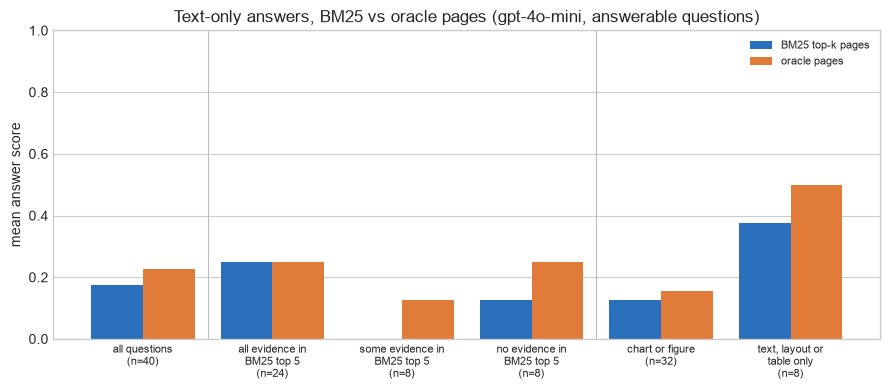

Groups are small (see n). Bars show where the errors sit; they are not precise estimates.


In [38]:
import textwrap

if not paired.empty:
    retrieval_order = [f"{amount} evidence in BM25 top {gen_k}" for amount in ("all", "some", "no")]
    groups = [
        ("all questions", paired),
        *[(name, paired[paired["retrieval_group"] == name]) for name in retrieval_order],
        *[(name, frame) for name, frame in paired.groupby("evidence_group")],
    ]
    groups = [(name, frame) for name, frame in groups if len(frame)]  # pilot mode can leave a group empty
    labels = [f"{textwrap.fill(name, 16)}\n(n={len(frame)})" for name, frame in groups]
    x = np.arange(len(groups))
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar(x - 0.2, [frame["bm25_score"].mean() for _, frame in groups], width=0.4, color="#2A6FBB", label="BM25 top-k pages")
    ax.bar(x + 0.2, [frame["oracle_score"].mean() for _, frame in groups], width=0.4, color="#E07B39", label="oracle pages")
    ax.axvline(0.5, color="#BBBBBB", linewidth=0.8)
    ax.axvline(sum(name in retrieval_order for name, _ in groups) + 0.5, color="#BBBBBB", linewidth=0.8)
    ax.grid(axis="x", visible=False)
    ax.set_xticks(x, labels, fontsize=8)
    ax.set(ylabel="mean answer score", ylim=(0, 1), title=f"Text-only answers, BM25 vs oracle pages ({SETTINGS['model_name']}, answerable questions)")
    ax.legend(loc="upper right", fontsize=8)
    plt.tight_layout()
    plt.show()
    print("Groups are small (see n). Bars show where the errors sit; they are not precise estimates.")


In [39]:
if not paired.empty:
    example_columns = ["qid", "retrieval_group", "evidence_group", "answer", "bm25_pred", "oracle_pred", "evidence_pages", "oracle_cited"]
    print("Fixed by the oracle pages (BM25 wrong, oracle correct):")
    display(paired[~paired["bm25_correct"] & paired["oracle_correct"]][example_columns])
    print("Broken by the oracle pages (BM25 correct, oracle wrong):")
    display(paired[paired["bm25_correct"] & ~paired["oracle_correct"]][example_columns])
    print("Still wrong with the evidence in context (first 8):")
    display(paired[~paired["oracle_correct"]][example_columns].head(8))


Fixed by the oracle pages (BM25 wrong, oracle correct):


,qid,retrieval_group,evidence_group,answer,bm25_pred,oracle_pred,evidence_pages,oracle_cited
19,mmlb-0359,some evidence in BM25 top 5,chart or figure,13%,25,13,"[11, 12]","[7, 11]"
32,mmlb-0740,no evidence in BM25 top 5,"text, layout or table only","['2015-03-24', '2015-03-25']","[2015-05-24, 2015-05-25]","[2015-03-24, 2015-03-25]","[1, 2]","[2, 3]"


Broken by the oracle pages (BM25 correct, oracle wrong):


,qid,retrieval_group,evidence_group,answer,bm25_pred,oracle_pred,evidence_pages,oracle_cited


Still wrong with the evidence in context (first 8):


,qid,retrieval_group,evidence_group,answer,bm25_pred,oracle_pred,evidence_pages,oracle_cited
1,mmlb-0034,all evidence in BM25 top 5,chart or figure,Europe IPO,Not answerable,Not answerable,[11],[]
2,mmlb-0035,some evidence in BM25 top 5,chart or figure,13,Not answerable,0,"[11, 13, 15, 16, 21, 22, 23, 24, 25, 26, 27, 31, 38]",[]
3,mmlb-0036,no evidence in BM25 top 5,chart or figure,5,0,3,"[14, 19, 20, 33, 37]","[19, 20, 37]"
4,mmlb-0037,no evidence in BM25 top 5,chart or figure,"['The Economist', 'TIME']","[Deutsche Bank Private Equity, Earlybird]","[Economist, Deutsche Bank Private Equity]",[33],"[19, 33]"
5,mmlb-0039,no evidence in BM25 top 5,chart or figure,10,1,2,"[6, 7, 8, 11, 18, 23, 24, 25, 28, 30]","[6, 28]"
6,mmlb-0041,all evidence in BM25 top 5,chart or figure,300 million,350,350,[26],[26]
7,mmlb-0094,all evidence in BM25 top 5,chart or figure,8,5,5,[15],"[15, 14, 13]"
8,mmlb-0095,all evidence in BM25 top 5,chart or figure,2.5-3cm,Not answerable,Not answerable,[6],[]


In [40]:
(run_dir / "oracle_summary.json").write_text(
    json.dumps(
        {
            "oracle_status": ORACLE_STATUS,
            "condition": SETTINGS["oracle_condition"],
            "oracle_qids": oracle_population["qid"].tolist(),
            "question_status": oracle_status_counts if oracle_rows else {},
            "metrics": {"bm25_same_questions": condition_metrics(scored[scored["qid"].isin(oracle_population["qid"])]) if oracle_metrics else None, "oracle": oracle_metrics},
        },
        indent=2,
        default=to_jsonable,
    )
)
with open(run_dir / "oracle_predictions.jsonl", "w") as handle:
    for record in oracle_rows:
        handle.write(json.dumps(record, default=to_jsonable) + "\n")
with open(run_dir / "oracle_errors.jsonl", "w") as handle:
    for record in oracle_error_rows:
        handle.write(json.dumps(record, default=to_jsonable) + "\n")
if not paired.empty:
    paired.to_csv(run_dir / "oracle_paired.csv", index=False)

pd.DataFrame([{"file": p.name, "bytes": p.stat().st_size} for p in sorted(run_dir.iterdir()) if p.name.startswith("oracle_")])


,file,bytes
0,oracle_errors.jsonl,0
1,oracle_paired.csv,6497
2,oracle_predictions.jsonl,17036
3,oracle_summary.json,1449


### Interpretation of the oracle-page condition

Run `20261119T220858Z_a351a532`, 40 answerable questions, gpt-4o-mini with text input in both conditions. All 40 oracle requests succeeded on the first attempt; `oracle_errors.jsonl` is empty.

- **Supplying the evidence fixes very little.** Accuracy rises from 0.175 to 0.225: 2 of the 33 wrong answers are fixed, and none of the 7 correct ones break. In the decomposition, +0.050 of the 0.825 error is fixed by supplying the evidence, and **0.775 remains with the evidence in context**. With text input, gpt-4o-mini on this subset is limited by reading, not by BM25.
- **The two fixes are real retrieval misses:** `mmlb-0359` (BM25 had page 11 but not page 12; the answer changes from 25 to the reference 13) and `mmlb-0740` (BM25 had neither page 1 nor page 2; the dates become correct). Both happened where the context actually changed. An earlier oracle run fixed the same two questions.
- **The model now cites evidence much more often** (0.650 → 0.875 of answerable questions cite an annotated page) without answering more correctly. It looks at the right page and still misreads it. For example, `mmlb-0041` cites page 26, its only evidence page, and answers 350 instead of 300 million in both conditions.
- **Visual evidence stays the weak point.** With the evidence in context, accuracy is 0.156 on questions whose evidence involves a chart or figure (n = 32) and 0.500 on text, layout or table evidence (n = 8). The gap is about as large as with BM25 (0.125 versus 0.375), so it is not caused by retrieval. Text extraction drops what charts and figures show. This is the hypothesis the multimodal condition tests.
- **False abstentions persist with the evidence present:** 3 answerable questions still get `"Not answerable"` (`mmlb-0034`, `-0095`, `-0315`). For `mmlb-0034` the single evidence page is a chart that BM25 had already ranked in the top 5.
- **Multi-page counting stays out of reach.** With all 13 or 10 evidence pages supplied, `mmlb-0035` and `mmlb-0039` answer 0 and 2 (references 13 and 10).

**Noise check.** On the 24 questions whose oracle context is identical to the BM25 context, 3 predictions differ between the two requests (for example 16 versus 15 on `mmlb-0363`), but **no score changes**. Across the three full BM25 runs of 2026-11-19, 4–6 of 57 predictions differed between any two runs, and again no score changed. Temperature 0 is not fully deterministic. On this subset the variation has so far only affected answers that were wrong in both runs, so a difference of 2 questions is unlikely to be noise. That is an observation from three runs, not a guarantee.

**Limits of this result.** 40 questions in 6 documents, and only 16 questions had a context that actually changed (8 with some and 8 with no evidence in the BM25 top 5). The oracle measures what retrieval can give **to this text reader**. A reader that can see images could benefit more from correct pages, so the conclusion "retrieval is not the bottleneck" must be re-checked in the multimodal condition.


## Validation checks

These assertions protect the properties the results depend on. If a later change breaks one, the notebook stops here instead of reporting a misleading number.

In [41]:
# 1. The subset is a pure function of the seed and the eligible list.
resampled = sorted(
    np.random.default_rng(SETTINGS["seed"]).choice(eligible_documents, size=SETTINGS["n_documents"], replace=False).tolist()
)
assert resampled == subset_documents

# 2. Every ranking is a permutation of its document's 1-based page numbers.
assert all(sorted(row.ranking) == list(range(1, row.page_count + 1)) for row in subset.itertuples())
assert all(sorted(row.ranking_native) == list(range(1, row.page_count + 1)) for row in subset.itertuples())

# 3. Metric ranges and monotonicity.
metric_columns = [c for c in retrieval_population.columns if c.startswith(("recall@", "hit@", "native_recall@", "native_hit@"))]
assert all(retrieval_population[c].between(0, 1).all() for c in metric_columns)
assert retrieval_summary["BM25 Recall@k"].is_monotonic_increasing
assert (retrieval_summary["BM25 Hit@k"] >= retrieval_summary["BM25 Recall@k"] - 1e-12).all()

# 4. Unanswerable questions never enter the retrieval metrics.
assert retrieval_population["answerable"].all()

# 5. Recall and Hit differ on a cross-page case: one of two evidence pages retrieved.
assert recall_at_k([3, 7], [7, 1, 2], 1) == 0.5 and hit_at_k([3, 7], [7, 1, 2], 1) == 1.0

# 6. The saved settings can be read back and identify the same subset.
saved = json.loads((run_dir / "settings.json").read_text())
assert saved["subset_documents"] == subset_documents and saved["seed"] == SETTINGS["seed"]

# 7. The pilot is a fixed, stratified sample inside the subset.
assert len(pilot) == SETTINGS["pilot_size"] and set(pilot_qids) <= set(subset["qid"])
assert int((~pilot["answerable"]).sum()) == 1

# 8. Answer metrics exist only if every question of the answer population got a model response,
#    and their denominator is exactly that population.
if answer_metrics is not None:
    assert GENERATION_COMPLETE and set(scored["qid"]) == set(answer_population["qid"]) and answer_metrics["questions"] == len(answer_population)
    assert not scored["status"].isin(["api_error", "not_attempted"]).any()

# 10. Oracle condition: every evidence page is supplied, the context has max(k, |E|) pages, and it equals
#     the BM25 context exactly when BM25 already had all the evidence. Metrics exist only for a complete run.
oracle_checks = zip(oracle_population["evidence_pages"], oracle_population["oracle_pages"], oracle_population["identical_context"], oracle_population[f"recall@{gen_k}"])
for evidence, supplied, identical, recall in oracle_checks:
    assert set(evidence) <= set(supplied)
    assert len(supplied) == max(gen_k, len(set(evidence)))
    assert identical == (recall == 1.0)
if oracle_metrics is not None:
    assert ORACLE_COMPLETE and set(oracle_scored["qid"]) == set(oracle_population["qid"])
    assert all(list(s) == list(o) for s, o in zip(oracle_scored["supplied_pages"], oracle_scored["oracle_pages"]))
    assert set(paired["qid"]) == set(oracle_population["qid"]) and paired["answerable"].all()

# 9. No credential reaches the saved files (oracle files included).
for path in run_dir.iterdir():
    assert not SECRET_PATTERN.search(path.read_text()), f"key-like string in {path.name}"

print("All validation checks passed.")

All validation checks passed.


## Limitations

- **Development subset only:** 6 documents and 57 questions, sampled with seed 42 from the 125 PDFs of at most 15 MB. Questions are clustered by document. No confidence intervals are reported because 6 clusters are too few for them to be meaningful.
- **Answer metrics are local diagnostics.** The official GPT-4o extraction stage is replaced by structured output, so they are not comparable to published MMLongBench-Doc numbers.
- **Small, clustered sample.** One full run of 57 questions, 40 of them answerable, in 6 documents. One more correct answerable question moves answerable accuracy by 0.025. Treat differences between evidence types or documents as hypotheses. Temperature 0 does not guarantee identical replies across reruns.
- **Citation validity is vacuous for empty citations:** a `"Not answerable"` reply or an unparseable reply cites `[]`, which counts as valid. Read it together with the abstention and unparseable-reply counts.
- **Partial runs report nothing.** If one question fails at the API after retries, the whole answer table is withheld rather than averaged over the questions that succeeded. Rerun after fixing the cause.
- **Scoring parity was checked by hand-traced cases**, not by running the official `eval_score.py` side by side.
- **4 of 1,091 reference answers can never score 1.0** under the official rules (format `Int` with answers `21%`, `14:04 CET`, `yes`, `GPT-4`). Two of them (`mmlb-0733`, `mmlb-0735`) belong to a document in this subset.
- **Text only:** OCR of slides loses layout, and chart values become isolated numbers, so a text-only model cannot read a graphic.
- **The oracle is padded, not evidence-only.** It keeps k = 5 pages, so distractors stay in context (Step 13). An evidence-only oracle could score differently, because it also removes the distractors. Questions with more than 5 evidence pages receive longer contexts (10 and 13 pages here).
- **Run-to-run variation at temperature 0:** 3–6 predictions out of 40–57 differ between identical requests. No score has changed so far, but a single run cannot rule out a one-question swing.
- **Untuned retriever:** BM25 uses default parameters, with no stop-word list and no stemming. The OCR threshold of 30 words is a heuristic.

## Failure case to remember

Every page of the `germanwings` deck has fewer than 30 native words. On native text, almost every page scores 0, BM25 effectively returns pages in document order, and Recall@5 is 0.091 — below the random reference of 0.217. With the OCR fallback it is 0.788. This silent failure has no error message, and it was only visible because extraction statistics were inspected before the metrics were trusted.

## Next step

1. Done on 2026-11-19: smoke, then pilot (5 questions), then full (57 questions, about 108k prompt tokens), with no API errors.
2. Done on 2026-11-19: **oracle-page condition** (Step 13). Answerable accuracy rises only from 0.175 to 0.225 with the evidence in context, so text reading, not BM25, limits this pipeline.
3. Add the **multimodal condition**: send images of the same top-k pages, and of the oracle pages, to a vision-language model. This fills the image row of the README §6 table. Chart and figure questions (32 of 40, accuracy 0.156 even with oracle pages) are where a gain is expected.
4. Only after that, enlarge the subset (more documents or several seeds) to tighten the estimates.